# Is FP8 rounding behind the random-push escapes?

**The research question.** In iteration 4 of this research run, *fixed random directions* were added to Qwen3-8B's
task-specification hidden states (decoder blocks 12–23). They often changed **which algorithm the model writes**:
on the connected-components task (T10), the default `union_find` became `dfs` or `bfs`. These pushes were called
"escapes". Every one of those programs came from an **FP8 W8A8 engine**. This artifact asks whether the escapes are
a property of the **model** or of the **FP8 numerics**.

**The design.** The artifact re-runs iteration 4's 40 directions (seeds 9101–9140) under four numerics, all built
from one bf16 snapshot. Everything else is held fixed: the CRN sampling slots, the twin prompts and the absolute push
size.

| engine | weights | activations | role |
|---|---|---|---|
| **a** W8A8 | e4m3, per output channel | e4m3, per token | the iteration-4 engine |
| **b** W8A16 | e4m3 | bf16 | weight rounding only |
| **c** W16A8 | bf16 | e4m3 (fake-quantised, per token) | activation rounding only |
| **d** BF16 | bf16 | bf16 | full-precision reference |

**What the full run found.**
- **Verdict.** The literal verdict is **NOT_REPRODUCED_HIGH** on both tasks: bf16 escapes on almost the same
  directions as FP8.
- **Escape fraction.** At α = 2 on T10, the escape fraction E is 0.725 for a and 0.650 for d.
- **Per-direction agreement.** Spearman 0.96, κ 0.83.
- **The FP8 effect.** FP8 adds only a small per-slot boost on T10: the off-default rate is 0.583 vs 0.532, with
  discordant CRN slots 30:10 (exact McNemar p = 0.002).

**What this notebook runs.** The artifact's `method.py` dispatches ten steps. Three of them sample 6,075 new programs
from Qwen3-8B on an FP8-capable 16 GB GPU (about 4.3 GPU-hours). Engine a reuses iteration 4's rows, which it
reproduced byte for byte, so the analysis works on 9,245 labelled programs in all. A labeller (hidden tests, AST and
LLM judges) labels each program with its algorithm. Neither the sampling nor the labelling fits in a 10-minute CPU
notebook. Instead, this notebook works through five parts:

1. the pipeline map (`method.py`);
2. the artifact's **engine code** (`src/engines.py`) on a toy linear layer, to show what the four numerics do;
3. the **committed analysis code** (`src/escape.py`, `src/analysis.py`), replayed on **100 real labelled CRN
   slots**:
   - the subset is T10 at α = 2, screen slots of directions 9101–9110;
   - each slot carries the label and pass/fail of all four engines;
   - the analysis covers the two-stage escape rule, the direction-paired McNemar test, Tango CI, κ and Spearman,
     the CRN-paired slot flips, the verdict table and the landing algorithms;
4. the **independent stdlib re-derivation** with placebos (`src/rederive.py`);
5. a check of every recomputed number against the full run, followed by plots.

The code is the artifact's own, split into cells. Changes needed for the notebook are marked `# NOTEBOOK:`.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# Every package imported below is pre-installed on Colab (numpy, scipy, matplotlib, torch): nothing to install there.
# Locally they are installed at Colab's exact versions (torch as the CPU wheel; this notebook runs on CPU).
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')
    _pip('torch==2.9.0', '--index-url', 'https://download.pytorch.org/whl/cpu')

In [2]:
from __future__ import annotations

# method.py
import os
import subprocess
import sys
from pathlib import Path

# src/c6.py, src/escape.py, src/analysis.py, src/rederive.py
import copy
import json
import math
import random
from collections import Counter, defaultdict
from typing import Any, Iterable

import numpy as np
from scipy import stats

# src/engines.py (its loguru logger is only used by the 16 GB model loader, which is not run here)
import types

import torch
import torch.nn.functional as F

# src/figures6.py (without matplotlib.use("Agg"), so figures render inline)
import matplotlib
import matplotlib.pyplot as plt

print("numpy", np.__version__, "| torch", torch.__version__, "| matplotlib", matplotlib.__version__)

numpy 2.0.2 | torch 2.9.0+cpu | matplotlib 3.10.0


In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-6/experiment-29/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
meta = data["metadata"]
print(meta["title"])
print("selection:", meta["selection"])
for ds in data["datasets"]:
    print(f"dataset '{ds['dataset']}': {len(ds['examples'])} examples")
ex0 = data["datasets"][0]["examples"][0]
print(json.dumps({k: (v[:200] + " ..." if isinstance(v, str) and len(v) > 200 else v) for k, v in ex0.items()},
                 indent=1))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Is FP8 rounding behind the random-push escapes?
selection: task T10, alpha 2, screen slots (k 0-1 x templates W1-W5) of the 10 fixed random directions 9101-9110 (the artifact's REPRO directions; outcome-blind choice) = 100 CRN slots, each with all four engines' 'label|pass' (predict_a..predict_d)
dataset 'engine_pop': 100 examples
{
 "input": "[T10 | POP_d9101_a2.0 | template W1 | CRN slot k=0] Qwen3-8B prompt (thinking off, T=1.0, inverse-CDF CRN draw u_stream(T10,W1,0)): Do not use ship for this task. . . . . . . .\n\nTask: write a Python f ...",
 "output": "union_find|pass",
 "metadata_task": "T10",
 "metadata_arm": "POP_d9101_a2.0",
 "metadata_template": "W1",
 "metadata_k": 0,
 "metadata_family": "POP",
 "metadata_alpha": 2.0,
 "metadata_direction_seed": 9101,
 "metadata_phase": "screen",
 "metadata_engine_a_source": "this_run",
 "predict_a": "union_find|pass",
 "predict_b": "union_find|pass",
 "pr

## Configuration

This cell holds every tunable parameter. The values that come with the notebook are the original ones. With
them, the whole notebook ran in 52 s on CPU in a clean environment, install cell included; the analysis cells
themselves take a few seconds.

- **Directions.** The demo data holds the 100 screen slots of the 10 directions 9101–9110. `N_DIRECTIONS` uses the
  first *n* of them; the full run analysed all 40 directions.
- **Permutation and placebo counts.** These match `src/analysis.py` and `src/rederive.py`.
- **Toy layer.** The toy-layer sizes only affect the numerics illustration.

In [5]:
# ---- tunable parameters ----
TASK = "T10"              # task of the demo subset (connected components; default algorithm union_find)
N_DIRECTIONS = 10         # fixed random directions analysed (demo data: 9101-9110 -> max 10; full run: 40, seeds 9101-9140)
N_PERM_LANDINGS = 5000    # Monte-Carlo permutations of perm_chi2 in the landing test (original: 5000)
N_PLACEBO_P1 = 10000      # rederive placebo P1, engine labels shuffled within direction (original: 10000)
N_PLACEBO_P2 = 2000       # rederive placebo P2, direction pairing permuted (original: 2000)
PLACEBO_SEED = 7          # rederive placebo RNG seed (original: 7)
# toy linear layer for the numerics illustration (Qwen3-8B: hidden size 4096, MLP width 12288)
TOY_IN = 4096             # input features (illustration value: 4096)
TOY_OUT = 1024            # output features (illustration value: 1024)
TOY_TOKENS = 64           # token rows (illustration value: 64)
TOY_PUSH = 6.0            # norm of the toy push added to the first half of the token rows

## 1. The pipeline (`method.py`)

`uv run method.py <step>` runs one resumable step, and `uv run method.py all` runs them in order, with the labeller
in the background:

| step | script | what |
|---|---|---|
| setup | `src/setup_inputs.py` | copy and sha256-verify every earlier-artifact input |
| gates | `src/cpu_gates.py` | CPU gates C1–C5 and the iteration-4 relabel |
| commit0 | `src/make_commit0.py` | hash-chained pre-registration |
| label | `src/label_worker6.py` | label worker (hidden tests + AST + LLM judges), run in the background during generation |
| q1 | `src/gpu_q.py --phase q1` | weight set Q: unit tests, REPRO byte identity vs iteration 4 (exp22), exp19 PN check |
| b | `src/gpu_b.py` | weight set B: engines d and c |
| q2 | `src/gpu_q.py --phase q2` | weight set Q: engine b, diagnostics, B-sensitivity control |
| analyse | `src/analysis.py` | E per engine, McNemar, verdicts, PN, REPRO, landings, relabel table |
| rederive | `src/rederive.py` | stdlib re-derivation and placebos |
| figures | `src/figures6.py` | figures/ |
| outputs | `src/finalize6.py`, `src/outputs6.py` | results bookkeeping and method_out.json |

The `src/` scripts, the 16 GB model and the labeller are not part of this demo, so the cell below defines the
dispatcher unchanged but only prints its plan. The steps marked (\*) are replayed in-process further down.

In [6]:
ROOT = Path.cwd()   # NOTEBOOK: original Path(__file__).resolve().parent (the artifact folder; a notebook has no __file__)
PY = str(ROOT / ".venv" / "bin" / "python") if (ROOT / ".venv" / "bin" / "python").exists() else sys.executable
STEPS = {
    "setup": ["src/setup_inputs.py"],
    "gates": ["src/cpu_gates.py"],
    "commit0": ["src/make_commit0.py"],
    "label": ["src/label_worker6.py"],
    "q1": ["src/gpu_q.py", "--phase", "q1"],
    "b": ["src/gpu_b.py"],
    "q2": ["src/gpu_q.py", "--phase", "q2"],
    "analyse": ["src/analysis.py"],
    "rederive": ["src/rederive.py"],
    "figures": ["src/figures6.py"],
    "outputs": ["src/finalize6.py"],
}
ORDER = ["setup", "gates", "commit0", "q1", "b", "q2", "analyse", "rederive", "figures", "outputs"]


def run(step: str, extra: list[str]) -> int:
    env = dict(os.environ, PYTHONUNBUFFERED="1")
    if step in ("b",):
        env["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
    cmd = [PY, *STEPS[step], *extra]
    if step == "rederive":
        cmd = [sys.executable, "-I", *STEPS[step]]
    print("+", " ".join(cmd), flush=True)
    rc = subprocess.call(cmd, cwd=ROOT, env=env)
    if step == "outputs" and rc == 0:
        rc = subprocess.call([PY, "src/outputs6.py"], cwd=ROOT, env=env)
    return rc


def main() -> None:
    if len(sys.argv) < 2 or sys.argv[1] not in list(STEPS) + ["all"]:
        print(__doc__)
        sys.exit(1)
    step, extra = sys.argv[1], sys.argv[2:]
    if step != "all":
        sys.exit(run(step, extra))
    lab = subprocess.Popen([PY, "src/label_worker6.py"], cwd=ROOT, env=dict(os.environ, PYTHONUNBUFFERED="1"))
    try:
        for s in ORDER:
            if s == "analyse":
                (ROOT / "data" / "STOP_LABELLER").touch()
                lab.wait()
            rc = run(s, [])
            if rc != 0:
                print(f"step {s} failed with exit code {rc}")
                sys.exit(rc)
    finally:
        if lab.poll() is None:
            lab.terminate()


# NOTEBOOK: instead of main(), print the plan that `uv run method.py all` would execute
REPLAYED = {"analyse": "escape rule, McNemar/Tango/kappa/Spearman, slot flips, verdict, landings",
            "rederive": "stdlib re-derivation + placebos", "figures": "plots at the end"}
GPU_STEPS = {"q1": "GPU, ~8 min", "b": "GPU, ~2 h 38 min", "q2": "GPU, ~70 min (+21 min top-up)"}
print("label    (background) src/label_worker6.py   not run (hidden tests + AST + LLM judges)")
for s in ORDER:
    cmd = ["python -I", *STEPS[s]] if s == "rederive" else ["python", *STEPS[s]]
    note = f"(*) replayed here: {REPLAYED[s]}" if s in REPLAYED else (f"not run ({GPU_STEPS[s]})" if s in GPU_STEPS
                                                                      else "not run")
    print(f"{s:8s} {' '.join(cmd):34s} {note}")

label    (background) src/label_worker6.py   not run (hidden tests + AST + LLM judges)
setup    python src/setup_inputs.py         not run
gates    python src/cpu_gates.py            not run
commit0  python src/make_commit0.py         not run
q1       python src/gpu_q.py --phase q1     not run (GPU, ~8 min)
b        python src/gpu_b.py                not run (GPU, ~2 h 38 min)
q2       python src/gpu_q.py --phase q2     not run (GPU, ~70 min (+21 min top-up))
analyse  python src/analysis.py             (*) replayed here: escape rule, McNemar/Tango/kappa/Spearman, slot flips, verdict, landings
rederive python -I src/rederive.py          (*) replayed here: stdlib re-derivation + placebos
figures  python src/figures6.py             (*) replayed here: plots at the end
outputs  python src/finalize6.py            not run


## 2. Constants (`src/c6.py`)

These are the design constants of the artifact:

- **Engines.** The four engines are defined above.
- **Directions.** The 40 fixed random directions are seeds 9101–9140, and 9101–9110 are the REPRO directions.
- **Templates.** There are five prompt templates, W1–W5.
- **CRN slots.** The CRN slot index *k* has three uses:
  - the twin uses k 0–9 × W1–W5, which gives N = 50;
  - the screen uses k 0–1 × W1–W5, which gives N = 10;
  - the confirmation tops up to k 0–5, which gives N = 30.
- **Default algorithms.** `union_find` on T10, `dijkstra` on T2.

A program is **off-default** when its catalogue label is a known algorithm other than the default.

In [7]:
# --- src/c6.py ---
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
ENGINES = {"a": "W8A8", "b": "W8A16", "c": "W16A8", "d": "BF16"}
ENGINE_DESC = {
    "a": "e4m3 weights (per-output-channel absmax/448) x e4m3 activations (per-token absmax/448); torch._scaled_mm",
    "b": "e4m3 weights x bf16 activations; fp32 accumulate, x s_w, one rounding to bf16",
    "c": "bf16 weights x per-token e4m3 fake-quantised activations; fp32 accumulate, x s_x, one rounding to bf16",
    "d": "bf16 weights x bf16 activations (F.linear, cuBLAS)",
}
WEIGHT_SET = {"a": "Q", "b": "Q", "c": "B", "d": "B"}
TASKS = ("T10", "T2")
SEEDS_POP = list(range(9101, 9141))
REPRO_SEEDS = list(range(9101, 9111))
POSCTRL_SEED = 9004
TEMPLATES = ["W1", "W2", "W3", "W4", "W5"]
K_TWIN = list(range(10))          # twin N = 50 (k 0-9 x W1-W5)
K_SCREEN = [0, 1]                 # screen N = 10
K_CONFIRM = [2, 3, 4, 5]          # +20 -> pooled 30
DEFAULTS = {"T10": "union_find", "T2": "dijkstra", "T03": "full_sort"}
ESC_EXCESS = 0.20
ESC_PASS_FRAC = 0.8


def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


# NOTEBOOK: the algorithm catalogue per task comes from the vendored iteration-4 screen.catalogue() (vendor/ is not
# shipped with this demo); these are the same sets src/rederive.py hard-codes.
CAT = {"T10": {"bfs", "dfs", "label_propagation", "union_find"}, "T2": {"bf_spfa", "bidijkstra", "dial", "dijkstra",
                                                                       "floyd"}}

for e in ENGINES:
    print(f"{e} {ENGINES[e]:6s} (weight set {WEIGHT_SET[e]}): {ENGINE_DESC[e]}")
print(f"{MODEL_ID}@{MODEL_REVISION[:8]}; directions {SEEDS_POP[0]}-{SEEDS_POP[-1]}; defaults {DEFAULTS}")

a W8A8   (weight set Q): e4m3 weights (per-output-channel absmax/448) x e4m3 activations (per-token absmax/448); torch._scaled_mm
b W8A16  (weight set Q): e4m3 weights x bf16 activations; fp32 accumulate, x s_w, one rounding to bf16
c W16A8  (weight set B): bf16 weights x per-token e4m3 fake-quantised activations; fp32 accumulate, x s_x, one rounding to bf16
d BF16   (weight set B): bf16 weights x bf16 activations (F.linear, cuBLAS)
Qwen/Qwen3-8B@b968826d; directions 9101-9140; defaults {'T10': 'union_find', 'T2': 'dijkstra', 'T03': 'full_sort'}


## 3. What the four numerics do to one linear layer (`src/engines.py`)

All four engines come from **one** bf16 snapshot, and only the decoder `nn.Linear` layers change. Two weight sets
hold them:

- **Weight set Q.** The vendored iteration-4 `FP8Linear` stores e4m3 weight codes with one scale per output channel,
  `s_w = absmax(row)/448`. Engine **a** multiplies them with per-token e4m3 activations through `torch._scaled_mm`
  (FP8 tensor cores, sm_89+). Engine **b** casts the codes to bf16 and keeps bf16 activations.
- **Weight set B.** This set keeps bf16 weights. Engine **d** is plain `F.linear`. Engine **c** fake-quantises the
  activations per token (`actq`, the same quantiser as engine a).

The cell below copies these classes and functions unchanged. Two notebook-only additions make them run on CPU:

- **A shim for `torch.mm(..., out_dtype=torch.float32)`.** This call exists only on CUDA in torch 2.9. On CPU the
  shim computes the same math by upcasting the bf16 operands.
- **A stand-in for the vendored module `VE`.** It provides the two names the code uses.

Engine a's native row-wise `torch._scaled_mm` also needs a CUDA sm_89+ GPU: CPU `_scaled_mm` only supports
per-tensor scales. On CPU, the cell therefore runs the artifact's **exact-math emulation** `a_emul` instead. That
emulation was the reference of unit test U1, where the native kernel stayed within 1 bf16 ulp of it for ≥ 99.98% of
outputs.

In [8]:
# NOTEBOOK: CPU shim. torch.mm(x, w, out_dtype=torch.float32) (bf16 operands, fp32 accumulation) exists only on CUDA
# in torch 2.9; on CPU the same math is upcasting both bf16 operands to fp32 first (bf16 values and their pairwise
# products are exact in fp32, and the sum is accumulated in fp32; only the summation order can differ from cuBLAS).
_TORCH_MM = torch.mm


def _mm_out_dtype_cpu(a: torch.Tensor, b: torch.Tensor, *, out_dtype: torch.dtype | None = None) -> torch.Tensor:
    if out_dtype is not None and not a.is_cuda:
        return _TORCH_MM(a.to(out_dtype), b.to(out_dtype))
    return _TORCH_MM(a, b) if out_dtype is None else _TORCH_MM(a, b, out_dtype=out_dtype)


torch.mm = _mm_out_dtype_cpu

# --- vendored iteration-4 engine (vendor/exp22/src_base/engine.py), unchanged ---
FP8_MAX = 448.0
_ACT_CACHE: dict[str, Any] = {"x": None, "xq": None, "xs": None}


class FP8Linear(torch.nn.Module):
    """y = x W^T with W in float8_e4m3fn (per-output-channel scale) and x quantised per row at run time."""

    def __init__(self, lin: torch.nn.Linear, device: torch.device):
        super().__init__()
        W = lin.weight.data.to(device=device, dtype=torch.float32)
        s = W.abs().amax(dim=1, keepdim=True).clamp(min=1e-12) / FP8_MAX  # [N, 1]
        wq = (W / s).clamp_(-FP8_MAX, FP8_MAX).to(torch.float8_e4m3fn)  # [N, K] row-major
        self.register_buffer("wq_t", wq.t(), persistent=False)  # [K, N] column-major view (what _scaled_mm wants)
        self.register_buffer("w_scale", s.t().contiguous(), persistent=False)  # [1, N] fp32
        self.in_features = lin.in_features
        self.out_features = lin.out_features
        if lin.bias is not None:
            self.register_buffer("bias", lin.bias.data.to(device=device, dtype=torch.bfloat16), persistent=False)
        else:
            self.bias = None
        del W, wq

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        shp = x.shape
        if _ACT_CACHE["x"] is x:  # q/k/v and gate/up share one input tensor: quantise it once
            xq, xs = _ACT_CACHE["xq"], _ACT_CACHE["xs"]
        else:
            x2 = x.reshape(-1, shp[-1])
            xs = x2.abs().amax(dim=1, keepdim=True).float().clamp_(min=1e-12) / FP8_MAX
            xq = (x2.float() / xs).clamp_(-FP8_MAX, FP8_MAX).to(torch.float8_e4m3fn)
            _ACT_CACHE.update(x=x, xq=xq, xs=xs)
        out = torch._scaled_mm(xq, self.wq_t, scale_a=xs, scale_b=self.w_scale, out_dtype=torch.bfloat16)
        if self.bias is not None:
            out = out + self.bias
        return out.reshape(*shp[:-1], self.out_features)


# NOTEBOOK: src/engines.py does `import engine as VE` (the vendored module above); a namespace with the two names it
# uses stands in for it.
VE = types.SimpleNamespace(_ACT_CACHE=_ACT_CACHE, FP8Linear=FP8Linear)

# --- src/engines.py ---
MODE: dict[str, Any] = {"m": None, "b_impl": "cast"}


def actq(x2: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """Per-row e4m3 activation quantiser, the exact operations of the vendored FP8Linear.forward."""
    xs = x2.abs().amax(dim=1, keepdim=True).float().clamp_(min=1e-12) / FP8_MAX
    xq = (x2.float() / xs).clamp_(-FP8_MAX, FP8_MAX).to(torch.float8_e4m3fn)
    return xq, xs


def weight_quant(W: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """Per-output-channel e4m3 weight quantiser, the exact operations of the vendored FP8Linear.__init__."""
    W = W.float()
    s = W.abs().amax(dim=1, keepdim=True).clamp(min=1e-12) / FP8_MAX
    return (W / s).clamp_(-FP8_MAX, FP8_MAX).to(torch.float8_e4m3fn), s


def _cached_act(x: torch.Tensor, x2: torch.Tensor, as_bf16: bool) -> tuple[torch.Tensor, torch.Tensor]:
    c = VE._ACT_CACHE
    if c["x"] is x and c.get("tag") == ("bf16" if as_bf16 else "fp8"):
        return c["xq"], c["xs"]
    xq, xs = actq(x2)
    if as_bf16:
        xq = xq.to(torch.bfloat16)
    c.update(x=x, xq=xq, xs=xs, tag="bf16" if as_bf16 else "fp8")
    return xq, xs


# ------------------------------------------------------------------------------------------------ weight set Q
_NATIVE_FORWARD = VE.FP8Linear.forward


def _q_forward(self: Any, x: torch.Tensor) -> torch.Tensor:
    m = MODE["m"]
    if m == "a":
        if VE._ACT_CACHE.get("tag") not in (None, "fp8"):
            VE._ACT_CACHE.update(x=None, xq=None, xs=None, tag=None)
        return _NATIVE_FORWARD(self, x)
    shp = x.shape
    x2 = x.reshape(-1, shp[-1])
    if m == "b":
        if MODE["b_impl"] == "triton":
            import w8a16_triton
            y = w8a16_triton.w8a16_mm(x2, self.wq_t.t(), self.w_scale)
        else:
            wb = self.wq_t.t().to(torch.bfloat16)
            y = (torch.mm(x2, wb.t(), out_dtype=torch.float32) * self.w_scale).to(torch.bfloat16)
    elif m == "a_emul":
        q, s = _cached_act(x, x2, as_bf16=True)
        wb = self.wq_t.t().to(torch.bfloat16)
        y = (torch.mm(q, wb.t(), out_dtype=torch.float32) * s * self.w_scale).to(torch.bfloat16)
    else:
        raise ValueError(f"mode {m} is not a weight-set-Q mode")
    if self.bias is not None:
        y = y + self.bias
    return y.reshape(*shp[:-1], self.out_features)


# ------------------------------------------------------------------------------------------------ weight set B
class EngLinearB(torch.nn.Module):
    def __init__(self, lin: torch.nn.Linear, device: torch.device):
        super().__init__()
        self.weight = torch.nn.Parameter(lin.weight.data.to(device=device, dtype=torch.bfloat16), requires_grad=False)
        assert lin.bias is None
        self.in_features, self.out_features = lin.in_features, lin.out_features

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        m = MODE["m"]
        if m == "d":
            return F.linear(x, self.weight)
        if m == "c":
            shp = x.shape
            x2 = x.reshape(-1, shp[-1])
            q, s = _cached_act(x, x2, as_bf16=True)
            y = (torch.mm(q, self.weight.t(), out_dtype=torch.float32) * s).to(torch.bfloat16)
            return y.reshape(*shp[:-1], self.out_features)
        raise ValueError(f"mode {m} is not a weight-set-B mode")


def set_mode(m: str) -> None:
    MODE["m"] = m
    VE._ACT_CACHE.update(x=None, xq=None, xs=None, tag=None)


# load_q() installs the weight-set-Q forward on every FP8Linear exactly like this
VE.FP8Linear.forward = _q_forward

The next cell pushes a toy activation matrix through one toy layer in every engine. It compares each output with
the exact (fp64) product of the same bf16 operands.

The toy activations are Gaussian rows plus a few large-magnitude channels, like the outlier channels of an LLM
residual stream. Those outliers set the per-token absmax, and so the e4m3 scale.

It then computes the rounding diagnostics of `src/diag6.py` at one linear-input site. Writing r = x − dq(q(x)) for
the rounding error:

- the relative rounding error RMS(r) / RMS(x);
- how much the rounding error itself changes when a push moves the input, ‖r_push − r_twin‖ / ‖x_push − x_twin‖;
- the fraction of moved rows whose per-token scale s_x changes.

On the real model, per-token rounding was about 2.5% RMS at every site. Under an α = 2 push, the change in rounding
error was 6–12% of the activation change, and 70–100% of the moved rows got a new scale. The toy numbers illustrate
the mechanism; they are not those measurements.

In [9]:
torch.manual_seed(0)
dev = torch.device("cpu")
lin = torch.nn.Linear(TOY_IN, TOY_OUT, bias=False)
with torch.no_grad():
    lin.weight.normal_(0.0, 0.02)
x = torch.randn(TOY_TOKENS, TOY_IN)
x[:, :8] *= 20.0                      # a few outlier channels set the per-token absmax
x = x.to(torch.bfloat16)
qlin, blin = VE.FP8Linear(lin, dev), EngLinearB(lin, dev)   # weight set Q (e4m3 codes) and weight set B (bf16)
exact = x.double() @ lin.weight.data.to(torch.bfloat16).double().t()   # exact product of the bf16 operands

toy_err = {}
with torch.no_grad():
    for m, mod, name in (("a_emul", qlin, "a W8A8  (exact-math emulation of _scaled_mm)"), ("b", qlin, "b W8A16"),
                         ("c", blin, "c W16A8"), ("d", blin, "d BF16")):
        set_mode(m)
        y = mod(x)
        toy_err[m[0]] = float((y.double() - exact).pow(2).mean().sqrt() / exact.pow(2).mean().sqrt())
        print(f"{name:46s} relative RMS error of the layer output vs exact: {toy_err[m[0]]:7.3%}")

# src/diag6.py ROUNDING metrics at one linear-input site, for a toy push added to the first half of the token rows
u = torch.randn(TOY_IN, generator=torch.Generator().manual_seed(9101))
u /= u.norm()
pushed = (torch.arange(TOY_TOKENS) < TOY_TOKENS // 2)[:, None]
x_push = (x.float() + TOY_PUSH * u[None, :] * pushed).to(torch.bfloat16)
xp, xt = x_push.float(), x.float()
qp, sp = actq(x_push)
qt, st = actq(x)
rp = xp - qp.float() * sp
rt = xt - qt.float() * st
dx = (xp - xt).norm(dim=-1)
moved = dx > 0
toy_rnd = {"rel_rms": float((rp.pow(2).mean(-1).sqrt() / xp.pow(2).mean(-1).sqrt().clamp(min=1e-12)).median()),
           "amp": float(((rp - rt).norm(dim=-1)[moved] / dx[moved]).median()),
           "scale_changed": float((sp != st).float()[moved].mean())}
print(f"\nper-token e4m3 rounding error RMS(x - dq(q(x))) / RMS(x): {toy_rnd['rel_rms']:.2%}  (real model: ~2.5%)")
print(f"push-induced rounding change ||r_push - r_twin|| / ||x_push - x_twin||: {toy_rnd['amp']:.2f} "
      f"over {int(moved.sum())} moved rows (push norm {TOY_PUSH})")
print(f"moved rows whose per-token scale s_x changed: {toy_rnd['scale_changed']:.0%}")
if torch.cuda.is_available() and torch.cuda.get_device_capability() >= (8, 9):
    # NOTEBOOK: on an FP8-capable GPU (e.g. an L4) the native iteration-4 kernel can be compared with its emulation
    qg = VE.FP8Linear(lin, torch.device("cuda"))
    with torch.no_grad():
        set_mode("a")
        ya = qg(x.cuda())
        set_mode("a_emul")
        ye = qg(x.cuda())
    print("native torch._scaled_mm vs a_emul, fraction of identical outputs:", float((ya == ye).float().mean()))

a W8A8  (exact-math emulation of _scaled_mm)   relative RMS error of the layer output vs exact:  3.592%
b W8A16                                        relative RMS error of the layer output vs exact:  2.662%
c W16A8                                        relative RMS error of the layer output vs exact:  2.407%
d BF16                                         relative RMS error of the layer output vs exact:  0.165%

per-token e4m3 rounding error RMS(x - dq(q(x))) / RMS(x): 2.37%  (real model: ~2.5%)
push-induced rounding change ||r_push - r_twin|| / ||x_push - x_twin||: 0.40 over 32 moved rows (push norm 6.0)
moved rows whose per-token scale s_x changed: 22%


## 4. The labelled programs of the demo subset

In the full run, `analysis.load_all()` joined every generated program with its label, which takes two inputs:

- `data/raw/raw_<engine>.jsonl`, the token ids of every program;
- `data/labels.jsonl`, the labeller output.

One row is built per engine and CRN slot. In `method_out.json`, each slot is stored once, with
`predict_<engine> = "label|pass"` (or `"label|fail"`).

The cell below rebuilds the per-engine rows from those strings, with the fields the analysis reads; this is the only
new code in the analysis part. Two more inputs come from the metadata:

- **The twin summary per engine.** This is the off-default share and pass rate of the 50 unpushed twin programs.
  Each engine is scored against its *own* twin. The twin rows themselves are a separate dataset of the artifact.
- **Iteration 4's relabelled escape fraction.** The verdict table needs it.

In [10]:
def load_all_demo(examples: list[dict[str, Any]]) -> dict[str, dict[str, list[dict[str, Any]]]]:
    """NOTEBOOK stand-in for analysis.load_all(): rows per engine and task, built from predict_<engine> = 'label|pass'."""
    out: dict[str, dict[str, list[dict[str, Any]]]] = {}
    for ex in examples:
        for e in ENGINES:
            v = ex.get(f"predict_{e}")
            if v is None:
                continue
            label, verdict = v.rsplit("|", 1)
            out.setdefault(e, {}).setdefault(ex["metadata_task"], []).append({
                "engine": e, "task": ex["metadata_task"], "arm": ex["metadata_arm"],
                "template": ex["metadata_template"], "sample_id": int(ex["metadata_k"]),
                "family": ex["metadata_family"], "alpha": ex["metadata_alpha"],
                "direction_seed": ex["metadata_direction_seed"], "stage": ex["metadata_phase"],
                "label": label, "passed": verdict == "pass",
                "source": ex["metadata_engine_a_source"] if e == "a" else "this_run"})
    return out


examples = [ex for ex in data["datasets"][0]["examples"] if ex["metadata_task"] == TASK]
DEMO_SEEDS = sorted({ex["metadata_direction_seed"] for ex in examples})[:N_DIRECTIONS]
examples = [ex for ex in examples if ex["metadata_direction_seed"] in DEMO_SEEDS]
TWIN = meta["twin"]                  # per engine x task: twin share / pass (N = 50), as computed by escape.share()
E4 = meta["E_iter4_relabelled"]      # iteration-4 E(a) per task and alpha, relabelled (results/cpu_gates.json C4)
R = load_all_demo(examples)

print(f"{len(examples)} CRN slots: task {TASK}, directions {DEMO_SEEDS[0]}-{DEMO_SEEDS[-1]} ({len(DEMO_SEEDS)}), "
      f"alpha {sorted({ex['metadata_alpha'] for ex in examples})}, k {sorted({ex['metadata_k'] for ex in examples})}, "
      f"templates {sorted({ex['metadata_template'] for ex in examples})}")
for e in ENGINES:
    labs = Counter(f"{r['label']}|{'pass' if r['passed'] else 'fail'}" for r in R[e][TASK])
    print(f"engine {e} {ENGINES[e]:6s} twin off-default {TWIN[e][TASK]['k_off']}/{TWIN[e][TASK]['n_valid']}, "
          f"pass {TWIN[e][TASK]['pass']:.2f} | pushed slots: {dict(labs.most_common())}")

100 CRN slots: task T10, directions 9101-9110 (10), alpha [2.0], k [0, 1], templates ['W1', 'W2', 'W3', 'W4', 'W5']
engine a W8A8   twin off-default 0/50, pass 1.00 | pushed slots: {'dfs|pass': 51, 'union_find|pass': 44, 'bfs|pass': 4, 'dfs|fail': 1}
engine b W8A16  twin off-default 0/50, pass 1.00 | pushed slots: {'union_find|pass': 49, 'dfs|pass': 46, 'bfs|pass': 3, 'dfs|fail': 2}
engine c W16A8  twin off-default 0/50, pass 1.00 | pushed slots: {'union_find|pass': 54, 'dfs|pass': 39, 'bfs|pass': 4, 'dfs|fail': 3}
engine d BF16   twin off-default 0/50, pass 1.00 | pushed slots: {'union_find|pass': 51, 'dfs|pass': 43, 'bfs|pass': 4, 'dfs|fail': 2}


## 5. The two-stage escape rule (`src/escape.py`)

This rule is iteration 4's (exp22's), re-implemented from its committed text. A gate checked that this code
reproduces exp22's `escape.json` exactly.

- **Shares.** The off-default share is #(catalogue label ≠ default) / #valid. Labels `invalid` and `disputed` leave
  the denominator, and `other` counts as *not* off-default. The pass rate is the fraction of programs that pass the
  hidden tests.
- **Screen (N = 10, k 0–1).** A direction passes the screen when its off-default share exceeds the twin's by
  ≥ 0.20 *and* its pass rate is ≥ 0.8 × the twin's.
- **Confirmation (pooled N = 30, k 0–5).** A screen-passing direction is topped up to 30 rows. It is CONFIRMED if the
  excess stays ≥ 0.20, a one-sided exact binomial test against p0 = (k_twin + 0.5)/(n_twin + 1) gives p < 0.05, and
  the pass clause still holds.
- **Escape fraction.** E = confirmed / directions run.

NOTEBOOK change: `escape_table()` and `needs_confirmation()` accept the twin summary (`tw=`), because the demo
subset carries no TWIN rows.

In [11]:
"""exp22's two-stage escape rule, re-implemented from the text in predictions/c2_commit.json (committed here before
any decisive sample; gate C3 checks it reproduces exp22 results/escape.json exactly from exp22's own labels).

Rule text (c2_commit.json 'escape_confirmation'):
  Screen pass at N = 10: excess >= 0.20 over the twin (N = 50, k 0-9) and pass >= 0.8 x twin.
  CONFIRMED if the pooled 30 (k 0-5) keeps excess >= 0.20 with one-sided exact binomial p < 0.05 against
  p0 = (k_twin + 0.5) / (n_twin + 1), and pass >= 0.8 x twin. E_t(alpha) = confirmed / run.
Shares (exp22 analysis/common.py docstring): off-default share = #(catalogue label != default) / #valid, with
'invalid' and 'disputed' excluded from the denominator and 'other' counted as NOT off-default. Pass = passed the
hidden tests over all attempts. Screen rows = k in {0, 1}; pooled rows = k in 0..5; a cell is 'confirmed' only if it
passed the screen and has rows beyond the screen (topped up).
"""

EXCLUDE = ("invalid", "disputed")
TOL = 1e-12


def share(rows: Iterable[dict[str, Any]], cat: set[str], default: str) -> dict[str, Any]:
    rows = list(rows)
    valid = [r for r in rows if r["label"] not in EXCLUDE]
    off = sum(1 for r in valid if r["label"] in cat and r["label"] != default)
    n = len(valid)
    npass = sum(1 for r in rows if r["passed"])
    return {"n": len(rows), "n_valid": n, "k_off": off, "share": off / n if n else float("nan"),
            "pass": npass / len(rows) if rows else float("nan"), "k_pass": npass,
            "n_other": sum(1 for r in rows if r["label"] == "other"),
            "n_invalid": sum(1 for r in rows if r["label"] == "invalid"),
            "n_disputed": sum(1 for r in rows if r["label"] == "disputed")}


def binom_greater(k: int, n: int, p0: float) -> float:
    return float(stats.binomtest(k, n, p0, alternative="greater").pvalue) if n > 0 else 1.0


def twin_rows(rows: list[dict[str, Any]], kmax: int = 10) -> list[dict[str, Any]]:
    return [r for r in rows if r["arm"] == "TWIN" and int(r["sample_id"]) < kmax]


def cell_eval(cell_rows: list[dict[str, Any]], tw: dict[str, Any], cat: set[str], default: str) -> dict[str, Any]:
    p0 = (tw["k_off"] + 0.5) / (tw["n_valid"] + 1)
    first = [r for r in cell_rows if int(r["sample_id"]) in (0, 1)]
    pooled = [r for r in cell_rows if 0 <= int(r["sample_id"]) <= 5]
    f, pl = share(first, cat, default), share(pooled, cat, default)
    screen = bool(f["n_valid"] > 0 and f["share"] - tw["share"] >= ESC() - TOL
                  and f["pass"] >= PASSF() * tw["pass"] - TOL)
    topped = pl["n"] > f["n"]
    conf, pbin = False, None
    if screen and topped:
        pbin = binom_greater(pl["k_off"], pl["n_valid"], p0)
        conf = bool(pl["share"] - tw["share"] >= ESC() - TOL and pbin < 0.05
                    and pl["pass"] >= PASSF() * tw["pass"] - TOL)
    return {"first10": f, "pooled": pl, "screen_pass": screen, "topped_up": topped, "binom_p": pbin,
            "confirmed": conf, "excess_first10": f["share"] - tw["share"] if f["n_valid"] else None,
            "excess_pooled": pl["share"] - tw["share"] if pl["n_valid"] else None, "p0": p0}


def ESC() -> float:
    return 0.20


def PASSF() -> float:
    return 0.8


def escape_table(rows: list[dict[str, Any]], seeds: list[int], cat: set[str], default: str,
                 alphas: tuple[float, ...] = (1.0, 2.0), family: str = "POP",
                 tw: dict[str, Any] | None = None) -> dict[str, Any]:
    """rows: joined label rows of ONE engine and task (TWIN + POP arms). Returns twin stats, per-direction cells and
    E_t per alpha (confirmed / n_run, n_run = directions with any screen row at that alpha)."""
    tw = share(twin_rows(rows), cat, default) if tw is None else tw   # NOTEBOOK: `tw` = twin summary from the metadata
    pop = defaultdict(list)
    for r in rows:
        if r.get("family") == family and r.get("direction_seed") is not None:
            pop[(int(r["direction_seed"]), float(r["alpha"]))].append(r)
    cells: dict[str, dict[str, Any]] = {}
    E: dict[str, dict[str, Any]] = {}
    for a in alphas:
        n_run = n_screen = n_conf = 0
        for s in seeds:
            rr = pop.get((s, float(a)), [])
            if not any(int(r["sample_id"]) in (0, 1) for r in rr):
                continue
            n_run += 1
            c = cell_eval(rr, tw, cat, default)
            cells[f"{s}|{a}"] = c
            n_screen += c["screen_pass"]
            n_conf += c["confirmed"]
        E[str(a)] = {"n_run": n_run, "n_screen_pass": n_screen, "n_confirmed": n_conf,
                     "E_t": n_conf / n_run if n_run else float("nan"),
                     "E_screen": n_screen / n_run if n_run else float("nan")}
    return {"twin": tw, "cells": cells, "E_t": E}


def needs_confirmation(rows: list[dict[str, Any]], seeds: list[int], cat: set[str], default: str,
                       alpha: float, tw: dict[str, Any] | None = None) -> list[int]:
    """Directions whose screen passes at `alpha` and that are not yet topped up."""
    t = escape_table(rows, seeds, cat, default, alphas=(alpha,), tw=tw)   # NOTEBOOK: passes `tw` through
    out = []
    for s in seeds:
        c = t["cells"].get(f"{s}|{alpha}")
        if c and c["screen_pass"] and not c["topped_up"]:
            out.append(s)
    return out

## 6. Statistics (`src/analysis.py`)

These are the committed test statistics:

- **`mcnemar_exact`.** An exact McNemar test on paired binary indicators: two engines on the same directions, or on
  the same CRN slots.
- **`tango_ci`.** A Tango score CI for a paired difference. It sits beside every |x| ≤ 0.1 verdict clause, together
  with a TOST equivalence test at margin 0.1.
- **`holm`.** Holm's multiple-testing correction.
- **`kappa` and `spearman`.** Cohen's κ of the escape indicators, and the Spearman correlation of the per-direction
  off-default shares.
- **`perm_chi2`.** A Monte-Carlo permutation χ² test of independence, used to compare the landing compositions.

In [12]:
ENGS = ("a", "b", "c", "d")
TASKS = ("T10", "T2")
PAIRS = [("a", "d"), ("c", "d"), ("b", "d"), ("a", "c"), ("a", "b")]
PRIMARY = [("a", "d"), ("c", "d"), ("b", "d")]


def catalogue(task: str) -> set[str]:
    return set(CAT[task])    # NOTEBOOK: original `import cfg4; from screen import catalogue as cat; return set(cat(task))`


# ------------------------------------------------------------------------------------------------ statistics
def mcnemar_exact(x: list[int], y: list[int]) -> dict[str, Any]:
    n10 = sum(1 for a, b in zip(x, y) if a and not b)
    n01 = sum(1 for a, b in zip(x, y) if b and not a)
    m = n10 + n01
    p2 = 1.0 if m == 0 else min(1.0, 2 * stats.binom.cdf(min(n10, n01), m, 0.5))
    p_gt = 1.0 if m == 0 else float(stats.binom.sf(n10 - 1, m, 0.5))   # H1: P(x) > P(y)
    return {"n10": n10, "n01": n01, "p_two_sided": float(p2), "p_one_sided_x_gt_y": p_gt}


def tango_ci(n10: int, n01: int, n: int, level: float = 0.90) -> tuple[float, float]:
    """Tango (1998) score CI for the paired difference p_x - p_y = (n10 - n01) / n."""
    if n == 0:
        return (float("nan"), float("nan"))
    z = stats.norm.ppf(0.5 + level / 2)
    grid = np.linspace(-1, 1, 8001)
    ok = []
    for d in grid:
        A = 2 * n
        B = -n10 - n01 + (2 * n - n10 + n01) * d
        C = -n01 * d * (1 - d)
        disc = max(B * B - 4 * A * C, 0.0)
        q21 = (math.sqrt(disc) - B) / (2 * A)
        var = n * (2 * q21 + d * (1 - d))
        if var <= 0:
            stat = 0.0 if (n10 - n01 - n * d) == 0 else float("inf")
        else:
            stat = (n10 - n01 - n * d) / math.sqrt(var)
        if abs(stat) <= z:
            ok.append(d)
    return (float(min(ok)), float(max(ok))) if ok else (float("nan"), float("nan"))


def holm(ps: dict[str, float]) -> dict[str, float]:
    items = sorted(ps.items(), key=lambda kv: kv[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p))
        out[k] = run
    return out


def kappa(x: list[int], y: list[int]) -> float:
    n = len(x)
    if n == 0:
        return float("nan")
    po = sum(1 for a, b in zip(x, y) if a == b) / n
    px, py = sum(x) / n, sum(y) / n
    pe = px * py + (1 - px) * (1 - py)
    return float("nan") if pe == 1 else (po - pe) / (1 - pe)


def spearman(x: list[float], y: list[float]) -> float | None:
    xx = np.array(x, float)
    yy = np.array(y, float)
    ok = ~(np.isnan(xx) | np.isnan(yy))
    if ok.sum() < 3 or np.std(xx[ok]) == 0 or np.std(yy[ok]) == 0:
        return None
    return float(stats.spearmanr(xx[ok], yy[ok]).statistic)


def perm_chi2(table: np.ndarray, n_perm: int = 10000, seed: int = 0) -> dict[str, Any]:
    """Monte-Carlo permutation test of independence for an r x c table (Fisher-Freeman-Halton surrogate)."""
    table = np.asarray(table, int)
    table = table[:, table.sum(0) > 0]
    if table.shape[1] < 2 or (table.sum(1) == 0).any():
        return {"chi2": None, "p_perm": None, "table": table.tolist()}
    rows = np.repeat(np.arange(table.shape[0]), table.sum(1))
    cols = np.concatenate([np.repeat(np.arange(table.shape[1]), table[i]) for i in range(table.shape[0])])

    def chi2(r, c):
        t = np.zeros(table.shape)
        np.add.at(t, (r, c), 1)
        e = t.sum(1, keepdims=True) * t.sum(0, keepdims=True) / t.sum()
        return float(((t - e) ** 2 / np.where(e > 0, e, 1)).sum())
    obs = chi2(rows, cols)
    rng = np.random.default_rng(seed)
    ge = sum(chi2(rows, rng.permutation(cols)) >= obs - 1e-9 for _ in range(n_perm))
    return {"chi2": obs, "p_perm": (ge + 1) / (n_perm + 1), "n_perm": n_perm, "table": table.tolist()}

## 7. Escape fraction per engine (`analysis.escape_by_engine`)

Each engine is scored against its own twin, direction by direction.

The demo subset holds the screen rows (k 0–1) of every direction, so everything at the screen level is exact. That
covers the first-10 share, the pass rate, the screen pass and E_screen.

The 20 top-up rows (k 2–5) of the screen passers are not in the 100-slot subset. So `confirmation_complete` is
False and no direction can be confirmed here. The code reports exactly that, as it did in the full run for engine b
on T10, whose top-up was cut short by the time limit.

The last lines call `needs_confirmation()`, the function the GPU drivers used to decide which directions to top up
next.

In [13]:
# ------------------------------------------------------------------------------------------------ escape
def escape_by_engine(R) -> dict[str, Any]:
    out: dict[str, Any] = {}
    for e in ENGS:
        for t in TASKS:
            rr = R.get(e, {}).get(t)
            if not rr:
                continue
            alphas = tuple(sorted({float(r["alpha"]) for r in rr if r["family"] == "POP"
                                   and r.get("direction_seed") in SEEDS_POP} & {1.0, 2.0}))
            tab = escape_table(rr, SEEDS_POP, catalogue(t), DEFAULTS[t], alphas=alphas,
                               tw=TWIN[e][t])   # NOTEBOOK: twin summary from the metadata
            pc = escape_table(rr, [9004], catalogue(t), DEFAULTS[t], alphas=(1.0,),
                              tw=TWIN[e][t]) if t == "T2" else None   # NOTEBOOK: twin summary from the metadata
            per_alpha = {}
            for a in alphas:
                E = tab["E_t"][str(a)]
                cells = {s: tab["cells"].get(f"{s}|{a}") for s in SEEDS_POP}
                n_pass_untopped = sum(1 for c in cells.values() if c and c["screen_pass"] and c["pooled"]["n"] < 30)
                tw = tab["twin"]
                n_excess_only = sum(1 for c in cells.values() if c and not c["screen_pass"] and c["first10"]["n_valid"]
                                    and c["first10"]["share"] - tw["share"] >= 0.2 - 1e-12)
                per_alpha[str(a)] = {
                    **E, "n_excess_met_but_pass_clause_failed": n_excess_only,
                    "mean_share10": float(np.nanmean([c["first10"]["share"] for c in cells.values() if c])),
                    "mean_pass10": float(np.nanmean([c["first10"]["pass"] for c in cells.values() if c])),
                    "E_wilson": wilson(E["n_confirmed"], E["n_run"]) if E["n_run"] else None,
                    "E_screen_wilson": wilson(E["n_screen_pass"], E["n_run"]) if E["n_run"] else None,
                    "confirmation_complete": n_pass_untopped == 0, "n_screen_pass_not_confirmed_tested": n_pass_untopped,
                    "per_direction": {str(s): None if c is None else {
                        "share10": c["first10"]["share"], "pass10": c["first10"]["pass"], "screen": c["screen_pass"],
                        "confirmed": c["confirmed"], "share30": c["pooled"]["share"] if c["topped_up"] else None,
                        "n_invalid10": c["first10"]["n_invalid"], "binom_p": c["binom_p"]} for s, c in cells.items()}}
            out.setdefault(e, {})[t] = {"twin": tab["twin"], "alpha": per_alpha,
                                        "posctrl_9004_a1": None if pc is None else pc["cells"].get("9004|1.0")}
    return out


ESC_T = escape_by_engine(R)   # NOTEBOOK: analysis.main() calls this ESC; renamed so escape.py's ESC() stays callable
print(f"{TASK}, alpha 2, {len(DEMO_SEEDS)} directions; each engine against its own twin (N = 50)")
print("engine     twin off  twin pass  dirs  screen passes  E_screen [Wilson 95%]  mean share10  mean pass10  "
      "excess met / pass failed  confirmation complete")
for e in ENGS:
    v, tw = ESC_T[e][TASK]["alpha"]["2.0"], ESC_T[e][TASK]["twin"]
    lo, hi = v["E_screen_wilson"]
    print(f"{e} {ENGINES[e]:7s} {tw['share']:9.2f} {tw['pass']:10.2f} {v['n_run']:5d} {v['n_screen_pass']:14d}   "
          f"{v['E_screen']:.3f} [{lo:.2f}, {hi:.2f}] {v['mean_share10']:13.3f} {v['mean_pass10']:12.3f} "
          f"{v['n_excess_met_but_pass_clause_failed']:25d}  {v['confirmation_complete']}")

print("\nper direction: first-10 off-default share / pass rate, S = screen pass")
print("direction " + "".join(f"{e + ' ' + ENGINES[e]:>16s}" for e in ENGS))
for s in DEMO_SEEDS:
    cells = [ESC_T[e][TASK]["alpha"]["2.0"]["per_direction"][str(s)] for e in ENGS]
    print(f"{s:9d} " + "".join(f"{c['share10']:9.1f} / {c['pass10']:.1f}{' S' if c['screen'] else '  '}" for c in cells))

print("\nneeds_confirmation(): screen passers the GPU driver would top up next (k 2-5 x W1-W5 = 20 more slots each)")
for e in ENGS:
    print(f"  {e} {ENGINES[e]:6s}", needs_confirmation(R[e][TASK], SEEDS_POP, catalogue(TASK), DEFAULTS[TASK], 2.0,
                                                    tw=TWIN[e][TASK]))

T10, alpha 2, 10 directions; each engine against its own twin (N = 50)
engine     twin off  twin pass  dirs  screen passes  E_screen [Wilson 95%]  mean share10  mean pass10  excess met / pass failed  confirmation complete
a W8A8         0.00       1.00    10              8   0.800 [0.49, 0.94]         0.560        0.990                         0  False
b W8A16        0.00       1.00    10              8   0.800 [0.49, 0.94]         0.510        0.980                         0  False
c W16A8        0.00       1.00    10              7   0.700 [0.40, 0.89]         0.460        0.970                         1  False
d BF16         0.00       1.00    10              8   0.800 [0.49, 0.94]         0.490        0.980                         0  False

per direction: first-10 off-default share / pass rate, S = screen pass
direction           a W8A8         b W8A16         c W16A8          d BF16
     9101       0.0 / 1.0        0.0 / 1.0        0.0 / 1.0        0.0 / 1.0  
     9102       0.6 

## 8. Direction-paired engine contrasts (`analysis.pairs_table`)

For each engine pair, the escape indicators of the **same** directions are compared. The pairs are a–d, c–d, b–d,
a–c and a–b.

- **McNemar.** An exact McNemar test on the discordant directions: n10 escapes only under x, n01 only under y.
- **Equivalence.** The 90% Tango CI of the difference, and a TOST equivalence test at margin 0.1.
- **Agreement.** Cohen's κ of the indicators, and the Spearman correlation of the first-10 shares.

The confirmed level needs complete confirmation in both engines. So here the code records that level as incomplete
and computes the screen level. Holm's correction runs over the primary *confirmed* contrasts, so it is empty here.

In [14]:
def pairs_table(ESC) -> dict[str, Any]:
    out: dict[str, Any] = {}
    raw_p = {}
    for t in TASKS:
        for (x, y) in PAIRS:
            if x not in ESC or y not in ESC or t not in ESC[x] or t not in ESC[y]:
                continue
            px = ESC[x][t]["alpha"]["2.0"]["per_direction"]
            py = ESC[y][t]["alpha"]["2.0"]["per_direction"]
            common = [s for s in px if px[s] is not None and py.get(s) is not None]
            complete = (ESC[x][t]["alpha"]["2.0"]["confirmation_complete"]
                        and ESC[y][t]["alpha"]["2.0"]["confirmation_complete"])
            for level in ("confirmed", "screen"):
                if level == "confirmed" and not complete:
                    out[f"{t}|{x}-{y}|{level}"] = {"status": "confirmation incomplete for an engine; see screen level"}
                    continue
                xs = [int(px[s][level]) for s in common]
                ys = [int(py[s][level]) for s in common]
                mc = mcnemar_exact(xs, ys)
                lo, hi = tango_ci(mc["n10"], mc["n01"], len(common))
                diff = (sum(xs) - sum(ys)) / len(common) if common else float("nan")
                rec = {"n_dirs": len(common), "E_x": sum(xs) / len(common) if common else None,
                       "E_y": sum(ys) / len(common) if common else None, "diff": diff, **mc,
                       "tango90": [lo, hi], "tost_margin_0.1_equivalent": bool(lo > -0.1 and hi < 0.1),
                       "kappa": kappa(xs, ys),
                       "spearman_share10": spearman([px[s]["share10"] for s in common],
                                                    [py[s]["share10"] for s in common])}
                out[f"{t}|{x}-{y}|{level}"] = rec
                if level == "confirmed" and (x, y) in PRIMARY:
                    raw_p[f"{t}|{x}-{y}"] = mc["p_two_sided"]
    hp = holm(raw_p) if raw_p else {}
    for k, v in hp.items():
        out[f"{k}|confirmed"]["p_holm"] = v
    out["holm_family"] = sorted(raw_p)
    return out


PAIR = pairs_table(ESC_T)
fmt = lambda v, f: "-" if v is None or v != v else format(v, f)   # noqa: E731  (None / NaN -> '-')
print(f"{TASK}, screen level, {len(DEMO_SEEDS)} directions")
print("pair  E_x    E_y    diff    n10/n01  p (2-sided)  Tango 90% CI      TOST 0.1  kappa  Spearman share10")
for (x, y) in PAIRS:
    r = PAIR[f"{TASK}|{x}-{y}|screen"]
    print(f"{x}-{y}   {r['E_x']:.3f}  {r['E_y']:.3f}  {r['diff']:+.3f}  {r['n10']:3d}/{r['n01']:<3d}  {r['p_two_sided']:11.3f}  "
          f"[{r['tango90'][0]:+.2f}, {r['tango90'][1]:+.2f}]   {str(r['tost_margin_0.1_equivalent']):8s}  "
          f"{fmt(r['kappa'], '.2f'):>5s}  {fmt(r['spearman_share10'], '.2f'):>5s}")
print("confirmed level:", PAIR[f"{TASK}|a-d|confirmed"])

T10, screen level, 10 directions
pair  E_x    E_y    diff    n10/n01  p (2-sided)  Tango 90% CI      TOST 0.1  kappa  Spearman share10
a-d   0.800  0.800  +0.000    0/0          1.000  [-0.21, +0.21]   False      1.00   0.92
c-d   0.700  0.800  -0.100    0/1          1.000  [-0.35, +0.13]   False      0.74   0.87
b-d   0.800  0.800  +0.000    0/0          1.000  [-0.21, +0.21]   False      1.00   0.82
a-c   0.800  0.700  +0.100    1/0          1.000  [-0.13, +0.35]   False      0.74   0.94
a-b   0.800  0.800  +0.000    0/0          1.000  [-0.21, +0.21]   False      1.00   0.90
confirmed level: {'status': 'confirmation incomplete for an engine; see screen level'}


## 9. CRN-paired slot flips (`analysis.slot_flips`)

This is the finer test. Every pushed sample in one engine has a partner in the other engine drawn from the **same
CRN slot**: same direction, template and k, and the same uniforms for the inverse-CDF sampling. Each slot gives one
off-default indicator per engine, and an exact McNemar test compares the discordant slots.

In the full run, this is where FP8's small boost on T10 showed up. Over 400 screen slots, a vs d gave off-default
rates of 0.583 vs 0.532, with discordant slots 30:10 (p = 0.002). The demo runs the same code on its 100 slots.

In [15]:
def slot_flips(R) -> dict[str, Any]:
    """CRN-paired per-slot comparison of POP alpha-2 rows (same direction, template, k and uniforms in both engines):
    off-default indicator per slot, exact McNemar on the discordant slots, and label identity of the paired slots."""
    out: dict[str, Any] = {}
    for t in TASKS:
        cat, dft = catalogue(t), DEFAULTS[t]
        ind = {}
        labs = {}
        for e in ENGS:
            rr = [r for r in R.get(e, {}).get(t, []) if r["family"] == "POP" and r.get("alpha") == 2.0
                  and r.get("direction_seed") in SEEDS_POP and r["label"] not in ("invalid", "disputed")]
            ind[e] = {(r["direction_seed"], r["template"], int(r["sample_id"])): int(r["label"] in cat and r["label"] != dft)
                      for r in rr}
            labs[e] = {(r["direction_seed"], r["template"], int(r["sample_id"])): r["label"] for r in rr}
        for (x, y) in PAIRS:
            if not ind.get(x) or not ind.get(y):
                continue
            # primary: the screen slots (k 0-1 of all 40 directions; run in every engine, no selection);
            # secondary: every common slot (adds confirmation slots, which exist only for screen-passing cells)
            for tag, keep in (("", lambda k: k[2] in (0, 1)), ("|all_common_slots", lambda k: True)):
                common = sorted(k for k in set(ind[x]) & set(ind[y]) if keep(k))
                mc = mcnemar_exact([ind[x][k] for k in common], [ind[y][k] for k in common])
                out[f"{t}|{x}-{y}{tag}"] = {
                    "n_slots": len(common), **mc,
                    "same_label_frac": float(np.mean([labs[x][k] == labs[y][k] for k in common])) if common else None,
                    "offdefault_x": float(np.mean([ind[x][k] for k in common])) if common else None,
                    "offdefault_y": float(np.mean([ind[y][k] for k in common])) if common else None}
    return out


SF = slot_flips(R)
FULL = meta["full_run"]
print(f"{TASK}: CRN-paired screen slots under the alpha-2 pushes (demo | full run)")
print("pair  slots  off-default x  off-default y  discordant x:y  exact McNemar p  same label  | full run: slots, "
      "x, y, x:y, p")
for (x, y) in PAIRS:
    r, f = SF[f"{TASK}|{x}-{y}"], FULL["slot_flips"][f"{TASK}|{x}-{y}"]
    print(f"{x}-{y}  {r['n_slots']:5d}  {r['offdefault_x']:13.3f}  {r['offdefault_y']:13.3f}  {r['n10']:8d}:{r['n01']:<5d}  "
          f"{r['p_two_sided']:15.3g}  {r['same_label_frac']:10.3f}  | {f['n_slots']}, {f['offdefault_x']:.3f}, "
          f"{f['offdefault_y']:.3f}, {f['n10']}:{f['n01']}, {f['p_two_sided']:.2g}")

T10: CRN-paired screen slots under the alpha-2 pushes (demo | full run)
pair  slots  off-default x  off-default y  discordant x:y  exact McNemar p  same label  | full run: slots, x, y, x:y, p
a-d    100          0.560          0.490         9:2               0.0654       0.870  | 400, 0.583, 0.532, 30:10, 0.0022
c-d    100          0.460          0.490         4:7                0.549       0.880  | 400, 0.497, 0.532, 9:23, 0.02
b-d    100          0.510          0.490         5:3                0.727       0.910  | 399, 0.556, 0.531, 17:7, 0.064
a-c    100          0.560          0.460        13:3               0.0213       0.840  | 400, 0.583, 0.497, 45:11, 5.4e-06
a-b    100          0.560          0.510         7:2                 0.18       0.880  | 399, 0.581, 0.556, 20:10, 0.099


## 10. The pre-registered verdict table (`analysis.verdicts`)

COMMIT #0's decision table is applied to E(a), E(b), E(c) and E(d). The rules are tried in this order, and the
first that holds decides:

| verdict | condition |
|---|---|
| ACTIVATION_ROUNDING | E(c) − E(d) ≥ 0.2, \|E(a) − E(c)\| ≤ 0.1 and \|E(b) − E(d)\| ≤ 0.1 |
| WEIGHT | E(b) − E(d) ≥ 0.2 |
| INTERACTION | E(a) − E(d) ≥ 0.2 while E(b) − E(d) < 0.1 and E(c) − E(d) < 0.1 |
| NOT_REPRODUCED_LOW | E(a) − E(d) < 0.1 and E(a) < E_iter4(a) − 0.15 |
| NOT_REPRODUCED_HIGH | E(a) − E(d) < 0.1 and E(d) ≥ E_iter4(a) − 0.15 (bf16 escapes too) |
| MIXED | otherwise |

The *literal* reading uses the confirmed E. It is UNDECIDABLE here, because confirmation needs the top-up rows. The
*screen-level* reading uses E_screen and is exact on the demo rows. T2 has no rows in the demo subset, so both of
its readings are UNDECIDABLE.

In [16]:
def verdicts(ESC, PAIR, E4: dict[str, Any]) -> dict[str, Any]:
    out: dict[str, Any] = {}
    for t in TASKS:
        def E(e, level="E_t"):
            try:
                v = ESC[e][t]["alpha"]["2.0"]
            except KeyError:
                return None
            if level == "E_t" and not v["confirmation_complete"]:
                return None
            return v[level]
        Ea, Eb, Ec, Ed = (E(e) for e in ENGS)
        Ea_s, Eb_s, Ec_s, Ed_s = (E(e, "E_screen") for e in ENGS)
        e4 = E4[t]["2.0"]

        def rule(Ea, Eb, Ec, Ed, feas: bool = False):
            if None in (Ea, Ec, Ed):
                return "UNDECIDABLE (missing engine)", {}
            c1 = (Ec - Ed >= 0.2 - 1e-12) if not feas else (
                Ec - Ed >= (2 / 3) * (Ea - Ed) - 1e-12 and
                PAIR.get(f"{t}|c-d|confirmed", {}).get("p_one_sided_x_gt_y", 1) < 0.05)
            clauses = {"c-d": c1, "|a-c|<=0.1": abs(Ea - Ec) <= 0.1 + 1e-12,
                       "|b-d|<=0.1": None if Eb is None else abs(Eb - Ed) <= 0.1 + 1e-12}
            if clauses["c-d"] and clauses["|a-c|<=0.1"] and clauses["|b-d|<=0.1"]:
                return "ACTIVATION_ROUNDING", clauses
            if Eb is not None and Eb - Ed >= 0.2 - 1e-12:
                return "WEIGHT", clauses
            if Eb is not None and Ea - Ed >= 0.2 - 1e-12 and Eb - Ed < 0.1 and Ec - Ed < 0.1:
                return "INTERACTION", clauses
            if Ea - Ed < 0.1 and Ea < e4 - 0.15:
                return "NOT_REPRODUCED_LOW", clauses
            if Ea - Ed < 0.1 and Ed >= e4 - 0.15:
                return "NOT_REPRODUCED_HIGH", clauses
            if Eb is None:
                return "MIXED_OR_UNDECIDABLE (b missing)", clauses
            return "MIXED", clauses
        lit, cl = rule(Ea, Eb, Ec, Ed)
        scr, cls = rule(Ea_s, Eb_s, Ec_s, Ed_s)
        rec = {"E_alpha2": {"a": Ea, "b": Eb, "c": Ec, "d": Ed}, "E_screen_alpha2": {"a": Ea_s, "b": Eb_s, "c": Ec_s,
                                                                                    "d": Ed_s},
               "E_iter4_relabelled_a": e4, "literal_verdict": lit, "literal_clauses": cl,
               "screen_level_verdict": scr, "screen_level_clauses": cls}
        if min(E4[t]["1.0"], E4[t]["2.0"]) < 0.3:
            fv, fcl = rule(Ea, Eb, Ec, Ed, feas=True)
            rec["feasibility_reading"] = {"verdict": fv, "clauses": fcl,
                                          "rule": "E(c)-E(d) >= (2/3)(E(a)-E(d)) and one-sided exact McNemar c>d p<0.05"}
        out[t] = rec
    lits = [out[t]["literal_verdict"] for t in TASKS]
    out["claim"] = {"literal": lits[0] if len(set(lits)) == 1 else "TASKS_DISAGREE: " + " / ".join(lits),
                    "activation_rounding_claim_both_tasks": all(v == "ACTIVATION_ROUNDING" for v in lits)}
    return out


V = verdicts(ESC_T, PAIR, E4)
for t in TASKS:
    note = "" if t in ESC_T.get("a", {}) else ", no rows of this task in the demo subset"
    print(f"{t} (demo{note}): literal = {V[t]['literal_verdict']}; screen level = {V[t]['screen_level_verdict']} "
          f"with E_screen {V[t]['E_screen_alpha2']} and clauses {V[t]['screen_level_clauses']}")
    print(f"{t} (full run, 40 directions): literal = {FULL['verdict'][t]['literal_verdict']} with E "
          f"{FULL['verdict'][t]['E_alpha2']}; screen level = {FULL['verdict'][t]['screen_level_verdict']} with E_screen "
          f"{FULL['verdict'][t]['E_screen_alpha2']}; iteration-4 E(a) relabelled = {E4[t]['2.0']}")

T10 (demo): literal = UNDECIDABLE (missing engine); screen level = NOT_REPRODUCED_HIGH with E_screen {'a': 0.8, 'b': 0.8, 'c': 0.7, 'd': 0.8} and clauses {'c-d': False, '|a-c|<=0.1': True, '|b-d|<=0.1': True}
T10 (full run, 40 directions): literal = NOT_REPRODUCED_HIGH with E {'a': 0.725, 'b': None, 'c': 0.6, 'd': 0.65}; screen level = NOT_REPRODUCED_HIGH with E_screen {'a': 0.75, 'b': 0.7, 'c': 0.675, 'd': 0.675}; iteration-4 E(a) relabelled = 0.725
T2 (demo, no rows of this task in the demo subset): literal = UNDECIDABLE (missing engine); screen level = UNDECIDABLE (missing engine) with E_screen {'a': None, 'b': None, 'c': None, 'd': None} and clauses {}
T2 (full run, 40 directions): literal = NOT_REPRODUCED_HIGH with E {'a': 0.2, 'b': 0.125, 'c': 0.15, 'd': 0.15}; screen level = MIXED with E_screen {'a': 0.375, 'b': 0.2, 'c': 0.2, 'd': 0.225}; iteration-4 E(a) relabelled = 0.2


## 11. Where do the pushes land? (`analysis.landings`)

This section looks at the *correct* (passing) off-default programs written under the α = 2 pushes. It counts their
algorithms per engine. A permutation χ² test then asks whether engines a, c and d share one composition.

In [17]:
def landings(R) -> dict[str, Any]:
    out: dict[str, Any] = {}
    for t in TASKS:
        cat, dft = catalogue(t), DEFAULTS[t]
        comp = {}
        for e in ENGS:
            rr = [r for r in R.get(e, {}).get(t, []) if r["family"] == "POP" and r.get("alpha") == 2.0
                  and r["passed"] and r["label"] not in ("invalid", "disputed") and r["label"] != dft]
            comp[e] = dict(Counter(r["label"] for r in rr))
        labs = sorted({l for e in comp for l in comp[e]})
        sub = [e for e in ("a", "c", "d") if comp.get(e)]
        tab = np.array([[comp[e].get(l, 0) for l in labs] for e in sub]) if sub else np.zeros((0, 0))
        out[t] = {"composition_correct_offdefault": comp,
                  "top1": {e: (max(comp[e], key=comp[e].get) if comp[e] else None) for e in comp},
                  "in_catalogue": sorted(cat),
                  "ffh_perm_a_c_d": perm_chi2(tab, N_PERM_LANDINGS) if len(sub) >= 2 else None,   # NOTEBOOK: original n_perm 5000
                  "engines_in_test": sub, "labels": labs}
    return out


L = landings(R)
lt = L[TASK]
print(f"{TASK}: correct off-default programs under the alpha-2 pushes (demo slots)")
for e in ENGS:
    print(f"  {e} {ENGINES[e]:6s} {lt['composition_correct_offdefault'][e]}   "
          f"(full run: {FULL['landings'][TASK]['composition_correct_offdefault'][e]})")
p = lt["ffh_perm_a_c_d"]
print(f"permutation chi2 test a/c/d share one composition: chi2 = {fmt(p and p['chi2'], '.3f')}, "
      f"p = {fmt(p and p['p_perm'], '.3f')} (full run: p = {FULL['landings'][TASK]['ffh_perm_a_c_d_p']:.3f})")

T10: correct off-default programs under the alpha-2 pushes (demo slots)
  a W8A8   {'dfs': 51, 'bfs': 4}   (full run: {'dfs': 502, 'bfs': 110})
  b W8A16  {'dfs': 46, 'bfs': 3}   (full run: {'dfs': 410, 'bfs': 86})
  c W16A8  {'dfs': 39, 'bfs': 4}   (full run: {'dfs': 406, 'bfs': 67})
  d BF16   {'dfs': 43, 'bfs': 4}   (full run: {'dfs': 448, 'bfs': 82})
permutation chi2 test a/c/d share one composition: chi2 = 0.136, p = 1.000 (full run: p = 0.218)


## 12. Independent re-derivation with placebos (`src/rederive.py`)

`rederive.py` recomputes the headline numbers from the joined rows with the **Python standard library only**. It
uses no numpy or scipy (the exact binomial tail comes from `math.comb`) and does not import `escape.py` or
`analysis.py`. It compares its numbers field by field with the analysis outputs.

Two placebos must then destroy the effect:

- **P1.** The engine labels are shuffled within each direction: a direction's two escape indicators are swapped with
  probability 1/2. This gives the null distribution of the engine difference, and the observed difference is
  compared with it.
- **P2.** The direction pairing is permuted. When direction *i* of one engine is paired with a random direction of
  the other, κ must fall to about 0.

Notebook changes:

- `share`, `kappa` and `main` get an `rd_` prefix, because they share one namespace with `escape.py` and
  `analysis.py`.
- `derive()` takes the twin summary.
- `rd_main()` receives the in-memory rows and analysis outputs, instead of `data/samples.jsonl` and
  `results/*.json`.
- The draw counts come from the config.
- The P1 interval indices scale with the number of draws; at the original 10,000 they are identical.

In [18]:
"""Independent re-derivation of every headline from data/samples.jsonl with the Python standard library only (no
numpy/scipy, no import of src/escape.py or src/analysis.py), plus placebos that must lose the effect.

Re-derived: per engine x task the twin share/pass, per-direction screen and confirmation at alpha 2 (exact binomial
tail by math.comb), E and the screen-level E, the direction-paired discordance counts for a-d, c-d, b-d, a-c, a-b,
the literal verdict, the PN off-default shares. Compared field by field with results/escape_by_engine.json,
results/mcnemar.json, results/verdict.json and results/pn.json.
Placebos (10,000 draws each, seed 7):
  P1 engine labels shuffled within direction (each direction's two escape indicators swapped with prob 1/2):
     the a-d difference in E must fall inside the placebo's central 95% (i.e. the observed difference must be
     extreme relative to it) -- reported as the placebo two-sided p.
  P2 direction pairing permuted (engine x's direction i paired with engine y's direction pi(i)): the per-direction
     agreement (kappa) between a and c / a and d must drop to ~0 -- reported as the placebo distribution of kappa.
"""

CAT = {"T10": {"bfs", "dfs", "label_propagation", "union_find"}, "T2": {"bf_spfa", "bidijkstra", "dial", "dijkstra",
                                                                       "floyd"}}
DEFAULT = {"T10": "union_find", "T2": "dijkstra"}
SEEDS = list(range(9101, 9141))
ENGS = ("a", "b", "c", "d")


def rd_share(rows, task):
    valid = [r for r in rows if r["label"] not in ("invalid", "disputed")]
    off = sum(1 for r in valid if r["label"] in CAT[task] and r["label"] != DEFAULT[task])
    npass = sum(1 for r in rows if r["passed"])
    return off, len(valid), (off / len(valid) if valid else float("nan")), (npass / len(rows) if rows else float("nan"))


def binom_sf(k: int, n: int, p: float) -> float:
    return sum(math.comb(n, i) * p ** i * (1 - p) ** (n - i) for i in range(k, n + 1))


def derive(rows_e_t, task, twin=None):
    tw = [r for r in rows_e_t if r["arm"] == "TWIN" and int(r["sample_id"]) < 10]
    k_t, n_t, s_t, pass_t = rd_share(tw, task)
    if twin is not None:   # NOTEBOOK: the demo subset has no TWIN rows -> the twin counts from the metadata
        k_t, n_t, s_t, pass_t = twin["k_off"], twin["n_valid"], twin["share"], twin["pass"]
    p0 = (k_t + 0.5) / (n_t + 1)
    cells = defaultdict(list)
    for r in rows_e_t:
        if r["family"] == "POP" and r.get("alpha") == 2.0 and r.get("direction_seed") in SEEDS:
            cells[r["direction_seed"]].append(r)
    per = {}
    for s in SEEDS:
        rr = cells.get(s, [])
        first = [r for r in rr if int(r["sample_id"]) in (0, 1)]
        if not first:
            continue
        pooled = [r for r in rr if 0 <= int(r["sample_id"]) <= 5]
        k1, n1, s1, ps1 = rd_share(first, task)
        k3, n3, s3, ps3 = rd_share(pooled, task)
        scr = n1 > 0 and s1 - s_t >= 0.2 - 1e-12 and ps1 >= 0.8 * pass_t - 1e-12
        conf = False
        if scr and len(pooled) > len(first):
            conf = (s3 - s_t >= 0.2 - 1e-12 and binom_sf(k3, n3, p0) < 0.05 and ps3 >= 0.8 * pass_t - 1e-12)
        per[s] = {"screen": scr, "confirmed": conf, "topped": len(pooled) >= 30, "share10": s1}
    n = len(per)
    return {"twin": {"k_off": k_t, "n_valid": n_t, "share": s_t, "pass": pass_t}, "per": per, "n_run": n,
            "E": sum(v["confirmed"] for v in per.values()) / n if n else None,
            "E_screen": sum(v["screen"] for v in per.values()) / n if n else None,
            "complete": all(v["topped"] for v in per.values() if v["screen"])}


def rd_kappa(x, y):
    n = len(x)
    po = sum(a == b for a, b in zip(x, y)) / n
    px, py = sum(x) / n, sum(y) / n
    pe = px * py + (1 - px) * (1 - py)
    return float("nan") if pe == 1 else (po - pe) / (1 - pe)


def rd_main(rows, esc, pair, ver, twin) -> dict:
    # NOTEBOOK: the original main() reads data/samples.jsonl and results/{escape_by_engine,mcnemar,verdict}.json and
    # writes results/rederive.json; here the same objects are passed in and the result is returned.
    by = defaultdict(list)
    for r in rows:
        by[(r["engine"], r["task"])].append(r)
    D = {(e, t): derive(by[(e, t)], t, twin=twin[e][t]) for e in ENGS for t in CAT if by.get((e, t))}
    checks, mism = {}, []
    for (e, t), d in D.items():
        ref = esc[e][t]["alpha"]["2.0"]
        ok = (d["n_run"] == ref["n_run"] and abs((d["E"] or 0) * d["n_run"] - ref["n_confirmed"]) < 1e-9
              and abs((d["E_screen"] or 0) * d["n_run"] - ref["n_screen_pass"]) < 1e-9
              and d["twin"]["k_off"] == esc[e][t]["twin"]["k_off"] and d["twin"]["n_valid"] == esc[e][t]["twin"]["n_valid"])
        checks[f"{e}|{t}|E"] = {"rederived_E": d["E"], "rederived_E_screen": d["E_screen"], "analysis_n_confirmed":
                                ref["n_confirmed"], "analysis_n_screen": ref["n_screen_pass"], "match": ok}
        if not ok:
            mism.append(f"{e}|{t}|E")
    for (x, y) in (("a", "d"), ("c", "d"), ("b", "d"), ("a", "c"), ("a", "b")):
        for t in CAT:
            if (x, t) not in D or (y, t) not in D:
                continue
            px, py = D[(x, t)]["per"], D[(y, t)]["per"]
            common = sorted(set(px) & set(py))
            n10 = sum(1 for s in common if px[s]["confirmed"] and not py[s]["confirmed"])
            n01 = sum(1 for s in common if py[s]["confirmed"] and not px[s]["confirmed"])
            ref = pair.get(f"{t}|{x}-{y}|confirmed", {})
            if "n10" not in ref:      # analysis skipped the confirmed level (an engine's confirmation incomplete)
                ref = pair.get(f"{t}|{x}-{y}|screen", {})
                n10 = sum(1 for s in common if px[s]["screen"] and not py[s]["screen"])
                n01 = sum(1 for s in common if py[s]["screen"] and not px[s]["screen"])
            ok = ref.get("n10") == n10 and ref.get("n01") == n01
            checks[f"{t}|{x}-{y}|mcnemar"] = {"n10": n10, "n01": n01, "match": ok}
            if not ok:
                mism.append(f"{t}|{x}-{y}|mcnemar")
    # verdict re-derivation (literal, alpha 2)
    e4 = {t: ver[t]["E_iter4_relabelled_a"] for t in CAT}
    for t in CAT:
        E = {e: (D[(e, t)]["E"] if (e, t) in D and D[(e, t)]["complete"] else None) for e in ENGS}
        Ea, Eb, Ec, Ed = E["a"], E["b"], E["c"], E["d"]
        if None in (Ea, Ec, Ed):
            v = "UNDECIDABLE (missing engine)"
        elif Ec - Ed >= 0.2 - 1e-12 and abs(Ea - Ec) <= 0.1 + 1e-12 and Eb is not None and abs(Eb - Ed) <= 0.1 + 1e-12:
            v = "ACTIVATION_ROUNDING"
        elif Eb is not None and Eb - Ed >= 0.2 - 1e-12:
            v = "WEIGHT"
        elif Eb is not None and Ea - Ed >= 0.2 - 1e-12 and Eb - Ed < 0.1 and Ec - Ed < 0.1:
            v = "INTERACTION"
        elif Ea - Ed < 0.1 and Ea < e4[t] - 0.15:
            v = "NOT_REPRODUCED_LOW"
        elif Ea - Ed < 0.1 and Ed >= e4[t] - 0.15:
            v = "NOT_REPRODUCED_HIGH"
        elif Eb is None:
            v = "MIXED_OR_UNDECIDABLE (b missing)"
        else:
            v = "MIXED"
        ok = v == ver[t]["literal_verdict"]
        checks[f"{t}|verdict"] = {"rederived": v, "analysis": ver[t]["literal_verdict"], "match": ok}
        if not ok:
            mism.append(f"{t}|verdict")
    # placebos
    rng = random.Random(PLACEBO_SEED)   # NOTEBOOK: original random.Random(7)
    plc = {}
    for t in CAT:
        for (x, y) in (("a", "d"), ("c", "d"), ("a", "c")):
            if (x, t) not in D or (y, t) not in D:
                continue
            level = "confirmed" if D[(x, t)]["complete"] and D[(y, t)]["complete"] else "screen"
            px, py = D[(x, t)]["per"], D[(y, t)]["per"]
            common = sorted(set(px) & set(py))
            xs = [int(px[s][level]) for s in common]
            ys = [int(py[s][level]) for s in common]
            obs = (sum(xs) - sum(ys)) / len(common)
            null = []
            for _ in range(N_PLACEBO_P1):   # NOTEBOOK: original 10000
                d = 0
                for a, b in zip(xs, ys):
                    d += (a - b) if rng.random() < 0.5 else (b - a)
                null.append(d / len(common))
            p1 = (sum(1 for v in null if abs(v) >= abs(obs) - 1e-12) + 1) / (len(null) + 1)
            k_obs = rd_kappa(xs, ys)
            kn = []
            for _ in range(N_PLACEBO_P2):   # NOTEBOOK: original 2000
                perm = ys[:]
                rng.shuffle(perm)
                kn.append(rd_kappa(xs, perm))
            kn = [k for k in kn if k == k]
            kn.sort()
            plc[f"{t}|{x}-{y}|{level}"] = {
                "observed_diff": obs, "P1_shuffled_engine_labels_p": p1,
                # NOTEBOOK: original indices [250] and [9749] (10,000 draws); scaled so any draw count works
                "P1_null_central95": [sorted(null)[int(0.025 * len(null))], sorted(null)[int(0.975 * len(null)) - 1]],
                "observed_kappa": k_obs,
                "P2_permuted_pairing_kappa_median": kn[len(kn) // 2] if kn else None,
                "P2_permuted_pairing_kappa_central95": [kn[int(0.025 * len(kn))], kn[int(0.975 * len(kn)) - 1]] if kn else None}
    out = {"n_rows": len(rows), "checks": checks, "mismatches": mism, "all_match": not mism, "placebos": plc}
    return out


samples = [dict(r, engine=e) for e in R for t in R[e] for r in R[e][t]]   # rows as analysis.write_samples() stores them
RD = rd_main(samples, ESC_T, PAIR, V, TWIN)
print(f"re-derived from {RD['n_rows']} rows: all_match = {RD['all_match']}, mismatches = {RD['mismatches']}")
for k, v in RD["checks"].items():
    print(f"  {k:22s} {v}")
print("placebos (screen level):")
for k, v in RD["placebos"].items():
    c95, k95 = v["P1_null_central95"], v["P2_permuted_pairing_kappa_central95"]
    print(f"  {k}: observed diff {v['observed_diff']:+.3f}, P1 placebo p = {v['P1_shuffled_engine_labels_p']:.3f} "
          f"(null central 95%: [{c95[0]:+.2f}, {c95[1]:+.2f}]); observed kappa {fmt(v['observed_kappa'], '.2f')}, "
          f"P2 permuted-pairing kappa median {fmt(v['P2_permuted_pairing_kappa_median'], '.2f')}"
          + (f" (central 95%: [{k95[0]:+.2f}, {k95[1]:+.2f}])" if k95 else ""))

re-derived from 400 rows: all_match = True, mismatches = []
  a|T10|E                {'rederived_E': 0.0, 'rederived_E_screen': 0.8, 'analysis_n_confirmed': 0, 'analysis_n_screen': 8, 'match': True}
  b|T10|E                {'rederived_E': 0.0, 'rederived_E_screen': 0.8, 'analysis_n_confirmed': 0, 'analysis_n_screen': 8, 'match': True}
  c|T10|E                {'rederived_E': 0.0, 'rederived_E_screen': 0.7, 'analysis_n_confirmed': 0, 'analysis_n_screen': 7, 'match': True}
  d|T10|E                {'rederived_E': 0.0, 'rederived_E_screen': 0.8, 'analysis_n_confirmed': 0, 'analysis_n_screen': 8, 'match': True}
  T10|a-d|mcnemar        {'n10': 0, 'n01': 0, 'match': True}
  T10|c-d|mcnemar        {'n10': 0, 'n01': 1, 'match': True}
  T10|b-d|mcnemar        {'n10': 0, 'n01': 0, 'match': True}
  T10|a-c|mcnemar        {'n10': 1, 'n01': 0, 'match': True}
  T10|a-b|mcnemar        {'n10': 0, 'n01': 0, 'match': True}
  T10|verdict            {'rederived': 'UNDECIDABLE (missing engine)', 'analysi

## 13. Does the replay match the full run?

Every demo slot carries the full run's per-direction result for each engine, in `metadata_escape_<engine>`: the
first-10 share, the screen pass and the confirmation. The screen-level quantities depend only on the k 0–1 rows,
which the demo holds in full, so they must match **exactly**.

The last column shows what the full run's top-up then decided for each screen passer: C means confirmed, and `.`
means screen pass but not confirmed.

In [19]:
n_cmp, mism = 0, []
for s in DEMO_SEEDS:
    ex = next(x for x in examples if x["metadata_direction_seed"] == s)
    for e in ENGS:
        ref = ex[f"metadata_escape_{e}"]
        mine = ESC_T[e][TASK]["alpha"]["2.0"]["per_direction"][str(s)]
        n_cmp += 1
        if abs(ref["share10"] - mine["share10"]) > 1e-12 or ref["screen"] != mine["screen"]:
            mism.append((s, e, ref, mine))
print(f"per-direction first-10 share + screen pass: {n_cmp - len(mism)} of {n_cmp} direction x engine cells match the "
      f"full run exactly" + ("" if not mism else f"; differing: {mism}"))
print("\ndirection   " + "   ".join(f"{e} share10 screen full-run-conf" for e in ENGS))
for s in DEMO_SEEDS:
    ex = next(x for x in examples if x["metadata_direction_seed"] == s)
    cells = []
    for e in ENGS:
        mine = ESC_T[e][TASK]["alpha"]["2.0"]["per_direction"][str(s)]
        conf = ex[f"metadata_escape_{e}"]["confirmed"]
        cells.append(f"{mine['share10']:9.1f} {'S' if mine['screen'] else '-':>6s} "
                     f"{('C' if conf else '.') if mine['screen'] else '-':>13s}")
    print(f"{s:9d}  " + "   ".join(cells))

per-direction first-10 share + screen pass: 40 of 40 direction x engine cells match the full run exactly

direction   a share10 screen full-run-conf   b share10 screen full-run-conf   c share10 screen full-run-conf   d share10 screen full-run-conf
     9101        0.0      -             -         0.0      -             -         0.0      -             -         0.0      -             -
     9102        0.6      S             C         0.6      S             C         0.4      S             C         0.6      S             C
     9103        0.9      S             C         0.8      S             C         0.8      S             C         0.7      S             C
     9104        0.9      S             C         0.8      S             C         0.9      S             C         0.8      S             C
     9105        0.4      S             C         0.6      S             C         0.5      -             -         0.5      S             C
     9106        0.1      -             -      

## 14. Figures

The figures are drawn with the artifact's own figure code (`src/figures6.py`): its colours, engine names and
plotting functions, with `save()` showing figures inline. The heatmap uses two markers:

- **Ring.** A screen pass, computed here.
- **Filled dot.** A confirmed escape in the full run, taken from `metadata_escape_<engine>`, because confirmation
  needs the top-up rows.

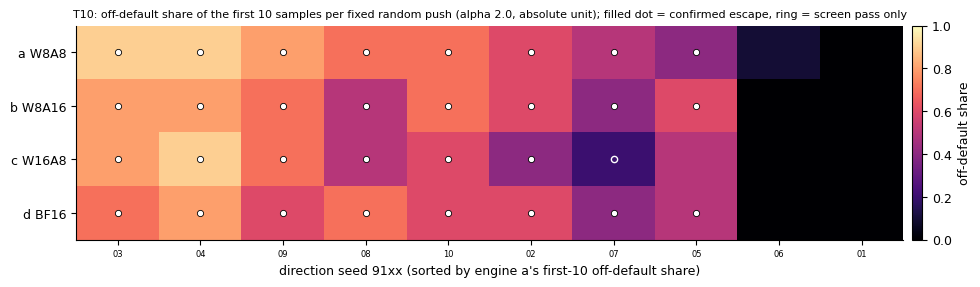

In [20]:
COL = {"a": "#0072B2", "b": "#E69F00", "c": "#009E73", "d": "#555555", "exp19_fp8": "#56B4E9"}
NAME = {"a": "a W8A8", "b": "b W8A16", "c": "c W16A8", "d": "d BF16"}
plt.rcParams.update({"font.size": 9, "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False,
                     "axes.spines.right": False})


def save(fig, name: str) -> None:
    plt.show()   # NOTEBOOK: original fig.savefig(FIGS / f"{name}.pdf" and .png) + plt.close(fig)


def heatmaps(ESC, alpha: str = "2.0") -> None:
    for t in ("T10", "T2"):
        engs = [e for e in ("a", "b", "c", "d") if e in ESC and t in ESC[e] and alpha in ESC[e][t]["alpha"]]
        if len(engs) < (1 if alpha == "2.0" else 2):
            continue
        pa = ESC["a"][t]["alpha"][alpha]["per_direction"]
        order = sorted([s for s in SEEDS_POP if pa.get(str(s))],   # NOTEBOOK: only the directions present
                       key=lambda s: -(pa[str(s)]["share10"] if pa.get(str(s)) else -1))
        M = np.full((len(engs), len(order)), np.nan)
        fig, ax = plt.subplots(figsize=(11, 1.1 + 0.42 * len(engs)))
        for i, e in enumerate(engs):
            pd = ESC[e][t]["alpha"][alpha]["per_direction"]
            for j, s in enumerate(order):
                c = pd.get(str(s))
                if c is None:
                    continue
                M[i, j] = c["share10"]
                if c["confirmed"]:
                    ax.plot(j, i, marker="o", ms=4.5, color="white", mec="black", mew=0.6)
                elif c["screen"]:
                    ax.plot(j, i, marker="o", ms=4.5, color="none", mec="white", mew=1.0)
        cm = plt.get_cmap("magma").copy()
        cm.set_bad("#dddddd")
        im = ax.imshow(np.ma.masked_invalid(M), aspect="auto", cmap=cm, vmin=0, vmax=1, zorder=0)
        ax.set_yticks(range(len(engs)), [NAME[e] for e in engs])
        ax.set_xticks(range(len(order)), [str(s)[-2:] for s in order], fontsize=6)
        ax.set_xlabel("direction seed 91xx (sorted by engine a's first-10 off-default share)")
        ax.set_title(f"{t}: off-default share of the first 10 samples per fixed random push (alpha {alpha}, absolute unit);"
                     f" filled dot = confirmed escape, ring = screen pass only", fontsize=8)
        fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01, label="off-default share")
        save(fig, f"heatmap_directions_{t}" + ("" if alpha == "2.0" else f"_alpha{alpha}"))


# the demo cannot confirm (no top-up rows): mark the full run's confirmed escapes on the demo's heatmap
ESC_PLOT = copy.deepcopy(ESC_T)
for ex in examples:
    for e in ENGS:
        ESC_PLOT[e][TASK]["alpha"]["2.0"]["per_direction"][str(ex["metadata_direction_seed"])]["confirmed"] = \
            ex[f"metadata_escape_{e}"]["confirmed"]
heatmaps(ESC_PLOT)

Next, the escape fraction per engine (demo and full run) and the per-direction agreement between engines.

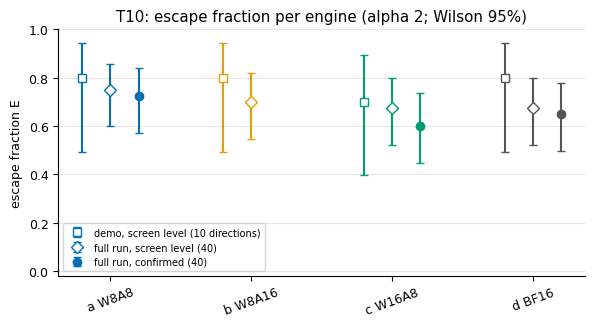

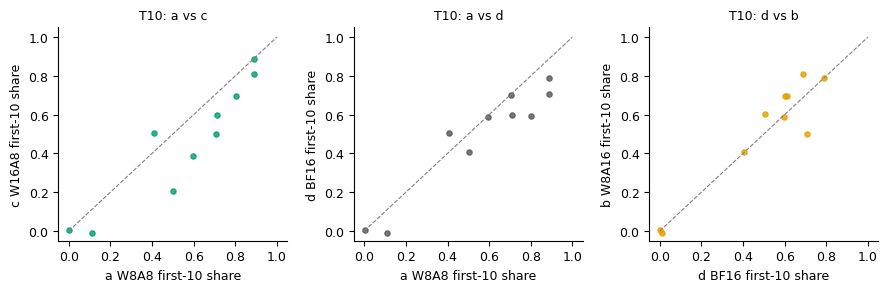

In [21]:
def e_by_engine_demo(ESC, FULL_ESC) -> None:
    """NOTEBOOK variant of figures6.e_by_engine(): the demo's screen-level E next to the full run's E (40 directions)."""
    fig, ax = plt.subplots(figsize=(6.8, 3.2))
    for i, e in enumerate(("a", "b", "c", "d")):
        v, f = ESC[e][TASK]["alpha"]["2.0"], FULL_ESC[e][TASK]
        for off, key, wk, src, mk, lab in ((-0.2, "E_screen", "E_screen_wilson", v, "s",
                                            f"demo, screen level ({len(DEMO_SEEDS)} directions)"),
                                           (0.0, "E_screen", "E_screen_wilson", f, "D", "full run, screen level (40)"),
                                           (0.2, "E_t", "E_wilson", f, "o", "full run, confirmed (40)")):
            if key == "E_t" and not src["confirmation_complete"]:
                continue
            y = src[key]
            lo, hi = src[wk]
            ax.errorbar(i + off, y, yerr=[[y - lo], [hi - y]], fmt=mk, color=COL[e], capsize=3,
                        mfc=COL[e] if key == "E_t" else "white", label=lab if e == "a" else None)
    ax.set_xticks(range(4), [NAME[e] for e in ("a", "b", "c", "d")], rotation=20)
    ax.set_title(f"{TASK}: escape fraction per engine (alpha 2; Wilson 95%)")
    ax.set_ylim(-0.02, 1.0)
    ax.grid(axis="y", alpha=0.3)
    ax.set_ylabel("escape fraction E")
    ax.legend(fontsize=7, loc="lower left")
    save(fig, "E_by_engine")


def scatter(ESC) -> None:
    pairs = [("a", "c"), ("a", "d"), ("d", "b")]
    fig, axes = plt.subplots(1, 3, figsize=(9, 3), squeeze=False)   # NOTEBOOK: one task row (original 2 x 3)
    for r, t in enumerate((TASK,)):
        for k, (x, y) in enumerate(pairs):
            ax = axes[r, k]
            if x not in ESC or y not in ESC or t not in ESC[x] or t not in ESC[y]:
                ax.set_axis_off()
                continue
            px = ESC[x][t]["alpha"]["2.0"]["per_direction"]
            py = ESC[y][t]["alpha"]["2.0"]["per_direction"]
            xs, ys = [], []
            for s in SEEDS_POP:
                if px.get(str(s)) and py.get(str(s)):
                    xs.append(px[str(s)]["share10"])
                    ys.append(py[str(s)]["share10"])
            rng = np.random.default_rng(0)
            ax.scatter(np.array(xs) + rng.uniform(-0.012, 0.012, len(xs)), np.array(ys) + rng.uniform(-0.012, 0.012, len(ys)),
                       s=14, color=COL[y], alpha=0.8)
            ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=0.8)
            ax.set_xlim(-0.05, 1.05)
            ax.set_ylim(-0.05, 1.05)
            ax.set_xlabel(f"{NAME[x]} first-10 share")
            ax.set_ylabel(f"{NAME[y]} first-10 share")
            ax.set_title(f"{t}: {x} vs {y}", fontsize=9)
    fig.tight_layout()
    save(fig, "per_direction_scatter")


e_by_engine_demo(ESC_T, FULL["escape_alpha2"])
scatter(ESC_T)

CRN-paired slot flips per engine pair, and the algorithms the correct off-default programs land on.

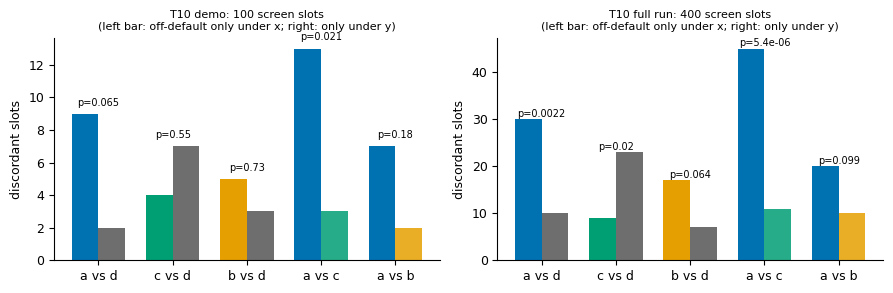

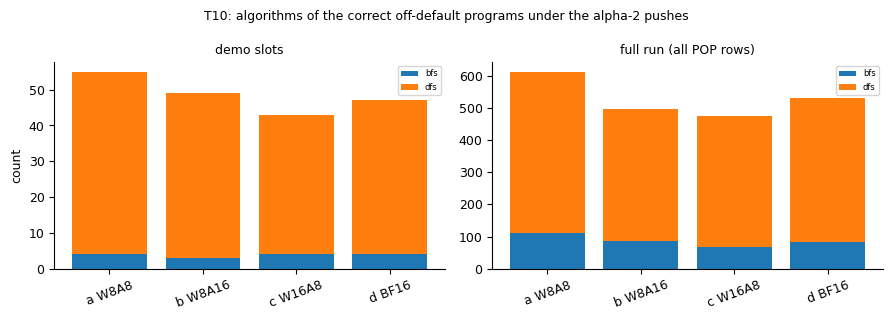

In [22]:
def slot_flip_fig(SF, FULL_SF) -> None:
    """NOTEBOOK figure: discordant CRN slots per engine pair (x off-default only vs y off-default only)."""
    fig, axes = plt.subplots(1, 2, figsize=(9, 3))
    for ax, (src, title) in zip(axes, ((SF, f"demo: {SF[f'{TASK}|a-d']['n_slots']} screen slots"),
                                       (FULL_SF, f"full run: {FULL_SF[f'{TASK}|a-d']['n_slots']} screen slots"))):
        for i, (x, y) in enumerate(PAIRS):
            r = src[f"{TASK}|{x}-{y}"]
            ax.bar(i - 0.18, r["n10"], width=0.36, color=COL[x], label=f"{x} only" if i == 0 else None)
            ax.bar(i + 0.18, r["n01"], width=0.36, color=COL[y], alpha=0.85)
            ax.text(i, max(r["n10"], r["n01"]) + 0.5, f"p={r['p_two_sided']:.2g}", ha="center", fontsize=7)
        ax.set_xticks(range(len(PAIRS)), [f"{x} vs {y}" for x, y in PAIRS])
        ax.set_ylabel("discordant slots")
        ax.set_title(f"{TASK} {title}\n(left bar: off-default only under x; right: only under y)", fontsize=8)
    fig.tight_layout()
    save(fig, "slot_flips")


def landings_fig_demo(L, FULL_L) -> None:
    """NOTEBOOK variant of figures6.landings_fig(): demo slots next to the full run, one task."""
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
    for ax, (comp, title) in zip(axes, ((L[TASK]["composition_correct_offdefault"], "demo slots"),
                                        (FULL_L[TASK]["composition_correct_offdefault"], "full run (all POP rows)"))):
        labs = sorted({l for e in comp for l in comp[e]})
        bottom = np.zeros(4)
        cols = plt.get_cmap("tab10")
        for k, lab in enumerate(labs):
            vals = np.array([comp.get(e, {}).get(lab, 0) for e in ("a", "b", "c", "d")], float)
            ax.bar(range(4), vals, bottom=bottom, color=cols(k % 10), label=lab)
            bottom += vals
        ax.set_xticks(range(4), [NAME[e] for e in ("a", "b", "c", "d")], rotation=20)
        ax.set_title(title, fontsize=9)
        ax.legend(fontsize=6)
    axes[0].set_ylabel("count")
    fig.suptitle(f"{TASK}: algorithms of the correct off-default programs under the alpha-2 pushes", fontsize=9)
    fig.tight_layout()
    save(fig, "landings")


slot_flip_fig(SF, FULL["slot_flips"])
landings_fig_demo(L, FULL["landings"])

Finally, a summary table puts the demo replay next to the full run.

In [23]:
# Summary: the demo replay next to the full run (40 directions; full-run numbers from the artifact's metadata)
fe = FULL["escape_alpha2"]
print(f"{'quantity':52s} {'demo (' + str(len(DEMO_SEEDS)) + ' directions)':>22s} {'full run (40 directions)':>26s}")
for e in ENGS:
    v, f = ESC_T[e][TASK]["alpha"]["2.0"], fe[e][TASK]
    conf = f"{f['E_t']:.3f}" if f["confirmation_complete"] else "incomplete"
    print(f"{'E_screen, engine ' + NAME[e]:52s} {v['E_screen']:22.3f} {f['E_screen']:26.3f}")
    print(f"{'E confirmed, engine ' + NAME[e]:52s} {'needs top-up rows':>22s} {conf:>26s}")
for (x, y) in (("a", "d"), ("c", "d"), ("b", "d")):
    r = PAIR[f"{TASK}|{x}-{y}|screen"]
    f = FULL["pairs"][f"{TASK}|{x}-{y}|screen"]
    print(f"{'screen-level discordant directions ' + x + ':' + y + ' (kappa)':52s} "
          f"{str(r['n10']) + ':' + str(r['n01']) + ' (' + fmt(r['kappa'], '.2f') + ')':>22s} "
          f"{str(f['n10']) + ':' + str(f['n01']) + ' (' + fmt(f['kappa'], '.2f') + ')':>26s}")
for (x, y) in (("a", "d"), ("c", "d"), ("b", "d")):
    r, f = SF[f"{TASK}|{x}-{y}"], FULL["slot_flips"][f"{TASK}|{x}-{y}"]
    print(f"{'CRN slot flips ' + x + ':' + y + ' (exact McNemar p)':52s} "
          f"{str(r['n10']) + ':' + str(r['n01']) + ' (p=' + format(r['p_two_sided'], '.2g') + ')':>22s} "
          f"{str(f['n10']) + ':' + str(f['n01']) + ' (p=' + format(f['p_two_sided'], '.2g') + ')':>26s}")
print(f"{'verdict, screen level':52s} {V[TASK]['screen_level_verdict']:>22s} "
      f"{FULL['verdict'][TASK]['screen_level_verdict']:>26s}")
print(f"{'verdict, literal (confirmed E)':52s} {'UNDECIDABLE (top-up)':>22s} "
      f"{FULL['verdict'][TASK]['literal_verdict']:>26s}")
print(f"{'stdlib re-derivation matches the analysis':52s} {str(RD['all_match']):>22s} {'True':>26s}")
pn = FULL["pn"][TASK]["PN_a2"]
print(f"{'per-sample plan noise PN alpha 2 (full run only)':52s} {'-':>22s} "
      f"{' '.join(e + ' ' + str(pn[e]['k_off']) + '/' + str(pn[e]['n_valid']) for e in ENGS):>26s}")

quantity                                               demo (10 directions)   full run (40 directions)
E_screen, engine a W8A8                                               0.800                      0.750
E confirmed, engine a W8A8                                needs top-up rows                      0.725
E_screen, engine b W8A16                                              0.800                      0.700
E confirmed, engine b W8A16                               needs top-up rows                 incomplete
E_screen, engine c W16A8                                              0.700                      0.675
E confirmed, engine c W16A8                               needs top-up rows                      0.600
E_screen, engine d BF16                                               0.800                      0.675
E confirmed, engine d BF16                                needs top-up rows                      0.650
screen-level discordant directions a:d (kappa)                   0:0 (1.0

## Takeaways

The numbers below are those printed by the cells above with the default configuration (all 10 demo directions).

- **The replay matches the full run.** The demo rows hold every screen slot of directions 9101–9110. On them, the
  committed escape rule gives the same per-direction first-10 shares and screen passes as the full run, in all 40
  direction × engine cells. The standard-library re-derivation agrees with the analysis code.
- **bf16 escapes too.**
  - **Same directions.** On these 10 directions, the bf16 engine (d) passes the screen on exactly the same 8
    directions as the FP8 engine (a): discordance 0:0, κ = 1.
  - **Same verdict.** The screen-level verdict is NOT_REPRODUCED_HIGH, as in the full run. The escapes are a property
    of Qwen3-8B under these pushes, not an FP8 artifact.
  - **The full run agrees.** Over all 40 directions, E(a) = 0.725 vs E(d) = 0.650, with discordance 3:0 and κ 0.83.
  - **The pass clause matters.** Engine c misses direction 9105 only through the pass clause: its off-default share
    is high enough, but only 7 of 10 programs pass the tests.
- **FP8's per-slot boost on T10 is small and needs many slots.**
  - **Demo.** On the 100 CRN-paired slots, FP8 (a) goes off-default where bf16 (d) does not in 9 slots, against
    2 the other way (p ≈ 0.07).
  - **Full run.** Over 400 slots the same comparison gives 30:10, p = 0.002.
  - **Where it comes from.** Activation rounding alone (c) does not raise the rate: c vs d is 4:7 here and 9:23 in
    the full run. This is why the artifact reports "model property plus a small FP8 boost, from weight rounding or
    the FP8 kernel".
- **The rounding itself is small.** Per-token e4m3 rounding perturbs a linear input by about 2.5% RMS, in the toy
  layer and in the real model. That flips individual samples, but it does not create the escapes.
- **To scale up.** Point the loader at more rows of the artifact's `full_method_out.json` (`engine_pop`, plus the
  confirmation slots k 2–5), add the twin rows, and pass `tw=None` so `escape_table()` derives the twin from the
  rows again. The same cells then compute the confirmed escapes and the literal verdict.